# Predicción de abandono de clientes (Customer Churn)

<div style="text-align: center;">
  <h2>Customer Churn Dataset</h2>
  <h3>Clasificación binaria con árbol de decisión, Naive Bayes y regresión logística</h3>
</div>

**Autor:** Pablo Alonso Zapatero 
---

## Resumen

El *churn* (abandono de clientes) es uno de los problemas más costosos para cualquier servicio por suscripción: captar un cliente nuevo suele resultar más caro que retener uno existente. Este cuaderno construye y compara varios clasificadores que, a partir del perfil y del comportamiento de cada cliente, predicen si abandonará el servicio (`Churn = 1`) o no (`Churn = 0`), y analiza qué factores pesan más en esa decisión.

**Resultados principales**

- **Datos:** 505.208 clientes, 10 variables predictoras (numéricas y categóricas) y una variable objetivo bastante equilibrada (≈ 55 % de los clientes abandona).
- **Mejor modelo:** árbol de decisión tras un estudio de ablación de variables, con una *accuracy* del **92,0 %** y capaz de detectar el **96,6 %** de los abandonos.
- **Factores más determinantes:** contrato mensual, más de 5 llamadas a soporte, retrasos de pago superiores a 20 días, gasto total bajo (menos de 500) y edad igual o superior a 60 años.
- **Enfoque de negocio:** penalizando más los abandonos no detectados (coste 4 veces mayor que una falsa alarma), el árbol detecta el **98,2 %** de los abandonos, a cambio de más falsas alarmas.

## Datos

Los datos proceden del [Customer Churn Dataset](https://www.kaggle.com/datasets/muhammadshahidazeem/customer-churn-dataset) de Muhammad Shahid Azeem (Kaggle, licencia GPL 2). Cada fila representa un cliente. Las variables disponibles son:

| Variable | Tipo | Descripción |
|---|---|---|
| `CustomerID` | Identificador | Identificador del cliente (no se usa para modelar). |
| `Age` | Numérica | Edad del cliente (18–65). |
| `Gender` | Categórica | Género (`Female`, `Male`). |
| `Tenure` | Numérica | Antigüedad del cliente (1–60, presumiblemente en meses). |
| `Usage.Frequency` | Numérica | Frecuencia de uso del servicio (1–30). |
| `Support.Calls` | Numérica | Número de llamadas al servicio de soporte (0–10). |
| `Payment.Delay` | Numérica | Retraso en el pago (0–30, presumiblemente en días). |
| `Subscription.Type` | Categórica | Tipo de suscripción (`Basic`, `Standard`, `Premium`). |
| `Contract.Length` | Categórica | Duración del contrato (`Monthly`, `Quarterly`, `Annual`). |
| `Total.Spend` | Numérica | Gasto total del cliente (100–1000). |
| `Last.Interaction` | Numérica | Tiempo transcurrido desde la última interacción (1–30). |
| `Churn` | **Objetivo** | `1` = el cliente abandona, `0` = permanece. |

## Metodología

El trabajo sigue las fases del proceso **KDD**:

1. **Exploración:** carga, limpieza y análisis individual de cada variable y de su relación con `Churn`.
2. **Preparación:** conversión de tipos, eliminación de nulos y discretización de las variables numéricas.
3. **Modelado y evaluación:** árbol de decisión (con y sin PCA), Naive Bayes y regresión logística, cada uno con su estudio de ablación de variables.
4. **Comparación y elección del modelo**, seguida de una mejora orientada al negocio mediante un árbol sensible al coste.

Los tres métodos se eligieron por su **interpretabilidad** (se puede explicar por qué predicen lo que predicen), su **eficiencia** con medio millón de filas y su adecuación a un problema de clasificación binaria con variables mixtas.

> **Nota sobre las métricas.** Todas las matrices de confusión se calculan con `caret`, que toma por defecto la clase `0` (no abandona) como clase *positiva*. Por eso la *Sensitivity* que aparece en las salidas mide qué porcentaje de los clientes que **permanecen** se clasifica bien, mientras que la *Specificity* equivale a la **capacidad de detectar abandonos** (`Churn = 1`). En la comparativa final se indica explícitamente a qué clase se refiere cada cifra.

## 1. Carga y preparación de los datos

Cargamos el dataset desde el fichero `Datos.csv` y echamos un primer vistazo a las primeras filas.

In [3]:
dfDatos <- read.csv("Datos.csv", header = TRUE, sep = ",")
head(dfDatos, 10)

,CustomerID,Age,Gender,Tenure,Usage.Frequency,Support.Calls,Payment.Delay,Subscription.Type,Contract.Length,Total.Spend,Last.Interaction,Churn
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
2,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
3,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
4,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
5,5,53,Female,58,24,9,2,Standard,Annual,533,18,0
6,6,30,Male,41,14,10,10,Premium,Monthly,500,29,0
7,7,47,Female,37,15,9,28,Basic,Quarterly,574,14,1
8,8,54,Female,36,11,0,18,Standard,Monthly,323,16,0
9,9,36,Male,20,5,10,8,Basic,Monthly,687,8,0


### Conversión de tipos

R importa como texto las columnas que contienen algún valor no numérico, por lo que convertimos explícitamente a tipo numérico las siete variables cuantitativas (`as.numeric()` / `as.integer()`). Los valores que no se pueden convertir pasan a `NA`; de ahí los avisos *«NAs introducidos por coerción»*, que son esperables en este paso. Las variables categóricas (`Gender`, `Subscription.Type`, `Contract.Length`) y la variable objetivo `Churn` se mantienen como texto.

In [4]:
dfDatos$Age <- as.numeric(dfDatos$Age)
dfDatos$Tenure <- as.numeric(dfDatos$Tenure)
dfDatos$Usage.Frequency <- as.numeric(dfDatos$Usage.Frequency)
dfDatos$Support.Calls <- as.numeric(dfDatos$Support.Calls)
dfDatos$Payment.Delay <- as.numeric(dfDatos$Payment.Delay)
dfDatos$Total.Spend <- as.numeric(dfDatos$Total.Spend)
dfDatos$Last.Interaction <- as.integer(dfDatos$Last.Interaction)
head(dfDatos, 10)

Warning message:
"NAs introducidos por coerción"
Warning message:
"NAs introducidos por coerción"
Warning message:
"NAs introducidos por coerción"
Warning message:
"NAs introducidos por coerción"
Warning message:
"NAs introducidos por coerción"
Warning message:
"NAs introducidos por coerción"
Warning message:
"NAs introducidos por coerción"


,CustomerID,Age,Gender,Tenure,Usage.Frequency,Support.Calls,Payment.Delay,Subscription.Type,Contract.Length,Total.Spend,Last.Interaction,Churn
,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<chr>
1,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
2,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
3,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
4,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
5,5,53,Female,58,24,9,2,Standard,Annual,533,18,0
6,6,30,Male,41,14,10,10,Premium,Monthly,500,29,0
7,7,47,Female,37,15,9,28,Basic,Quarterly,574,14,1
8,8,54,Female,36,11,0,18,Standard,Monthly,323,16,0
9,9,36,Male,20,5,10,8,Basic,Monthly,687,8,0


### Limpieza de valores nulos

Eliminamos las filas con valores nulos y comparamos el número de filas antes y después. Pasamos de **505.208 a 505.206** registros: solo se pierden 2 filas (menos del 0,001 %), por lo que descartarlas es la opción más sencilla y no introduce ningún sesgo apreciable. No es necesario imputar valores.

In [5]:
nrow(dfDatos)
dfDatosLimpio <- na.omit(dfDatos)
nrow(dfDatosLimpio)

[1] 505208

[1] 505206

## 2. Análisis exploratorio

### Resumen estadístico

El `summary()` ofrece una primera visión de los rangos y la tendencia central de cada variable:

- Los valores se mueven en rangos razonables, sin negativos ni valores imposibles: edades de 18 a 65 años, de 0 a 10 llamadas a soporte, retrasos de pago de 0 a 30 y gasto total entre 100 y 1000.
- Las variables tienen **escalas muy distintas** (el gasto llega a 1000 y las llamadas a soporte a 10). Esto será relevante más adelante: obliga a **estandarizar** las variables antes de aplicar PCA y condiciona la lectura de los coeficientes de la regresión logística.
- `Gender`, `Subscription.Type`, `Contract.Length` y `Churn` aparecen como texto (`character`), por lo que el resumen no calcula estadísticos para ellas.

In [6]:
summary(dfDatosLimpio)

  CustomerID             Age          Gender              Tenure     
 Length:505206      Min.   :18.0   Length:505206      Min.   : 1.00  
 Class :character   1st Qu.:29.0   Class :character   1st Qu.:16.00  
 Mode  :character   Median :40.0   Mode  :character   Median :32.00  
                    Mean   :39.7                      Mean   :31.35  
                    3rd Qu.:49.0                      3rd Qu.:46.00  
                    Max.   :65.0                      Max.   :60.00  
 Usage.Frequency Support.Calls    Payment.Delay  Subscription.Type 
 Min.   : 1.00   Min.   : 0.000   Min.   : 0.0   Length:505206     
 1st Qu.: 8.00   1st Qu.: 1.000   1st Qu.: 6.0   Class :character  
 Median :16.00   Median : 3.000   Median :13.0   Mode  :character  
 Mean   :15.71   Mean   : 3.833   Mean   :13.5                     
 3rd Qu.:23.00   3rd Qu.: 6.000   3rd Qu.:20.0                     
 Max.   :30.00   Max.   :10.000   Max.   :30.0                     
 Contract.Length     Total.Spend  

In [7]:
# Crear una copia de los datos para que el modelo lineal use las variables iniciales sin ser modificadas
dfDatosLineal <- dfDatosLimpio

Antes de transformar nada, guardamos una **copia con las variables originales** (`dfDatosLineal`). La regresión logística trabajará con las variables numéricas tal cual, mientras que el árbol de decisión y Naive Bayes usarán también versiones discretizadas.

### Distribución de cada variable

Representamos la distribución de todas las variables: histogramas para las numéricas y diagramas de barras para las categóricas. Lo más destacable:

- **`Age`:** hay más clientes entre los 20 y los 50 años que por encima de los 50. El aspecto «dentado» del histograma es un artefacto de repartir valores enteros en 30 intervalos, no un patrón real.
- **`Tenure`:** distribución casi uniforme, con un pico en el valor máximo (60).
- **`Support.Calls`:** la mayoría de los clientes realiza entre 0 y 3 llamadas; a partir de 5 llamadas la frecuencia se estabiliza.
- **`Total.Spend`:** la densidad de clientes se duplica aproximadamente a partir de un gasto de 500.
- **`Last.Interaction`:** son más frecuentes las interacciones recientes (primeros 15 días) que las más antiguas.
- **Categóricas:** hay algo más de hombres (≈ 55 %) que de mujeres, y los contratos mensuales (≈ 22 %) son minoritarios frente a los trimestrales y anuales (≈ 39 % cada uno).
- **`Churn`:** la clase `1` (abandona) es ligeramente mayoritaria (≈ 55 %). El desbalance es leve, por lo que no es necesario remuestrear.

Cargando paquete requerido: tidyverse



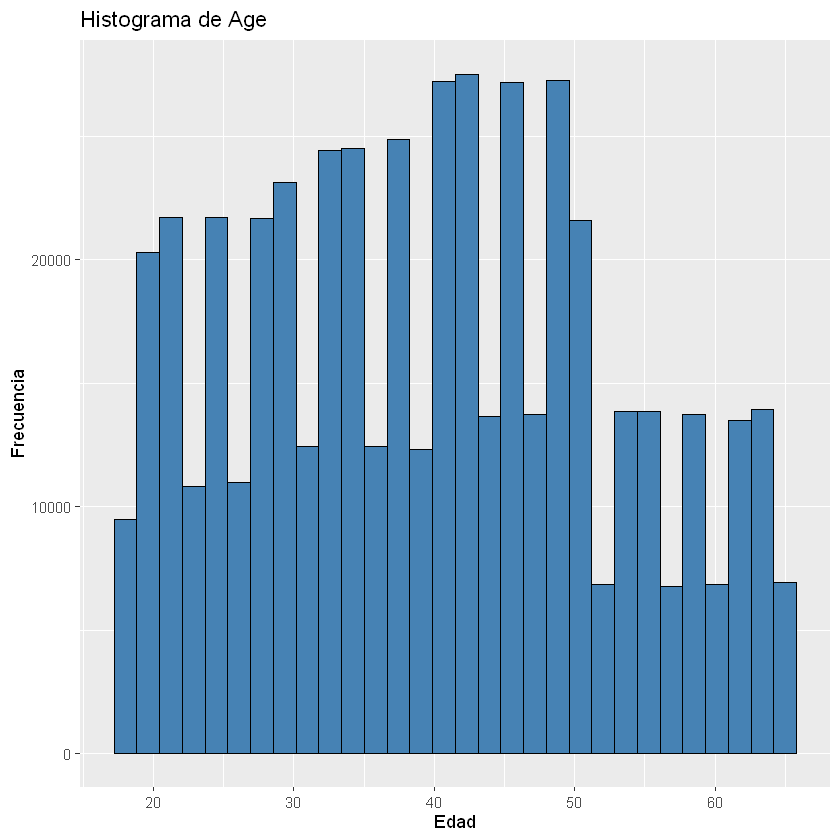

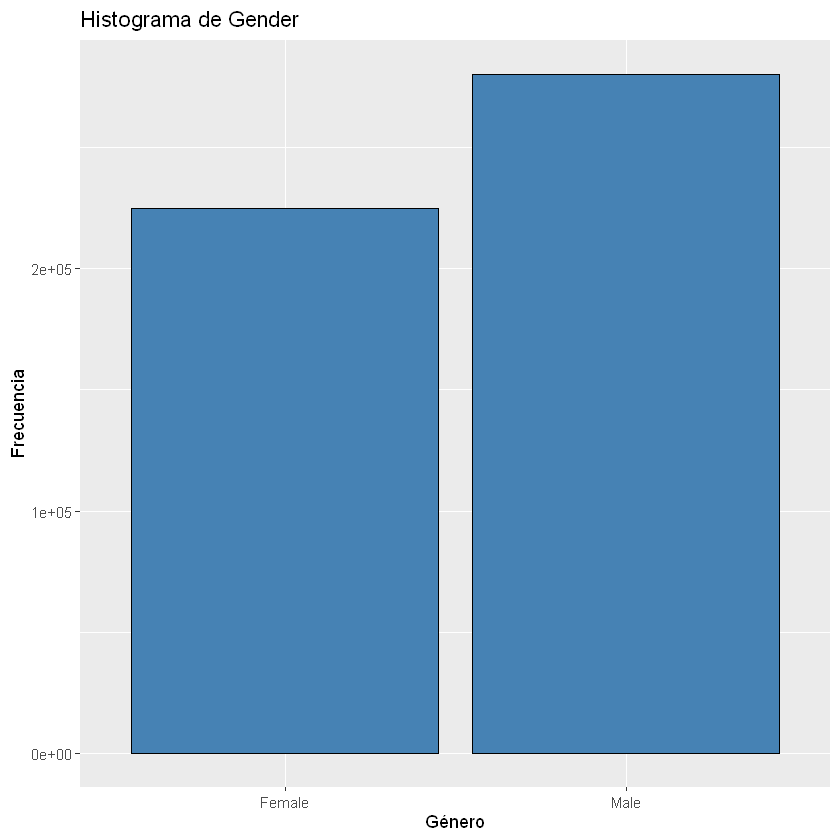

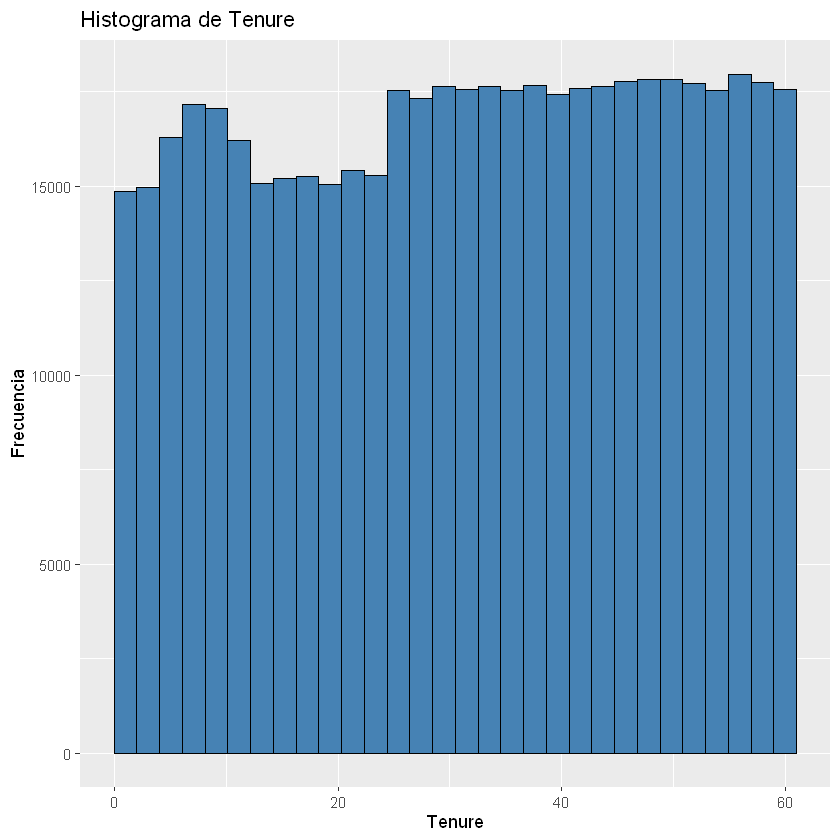

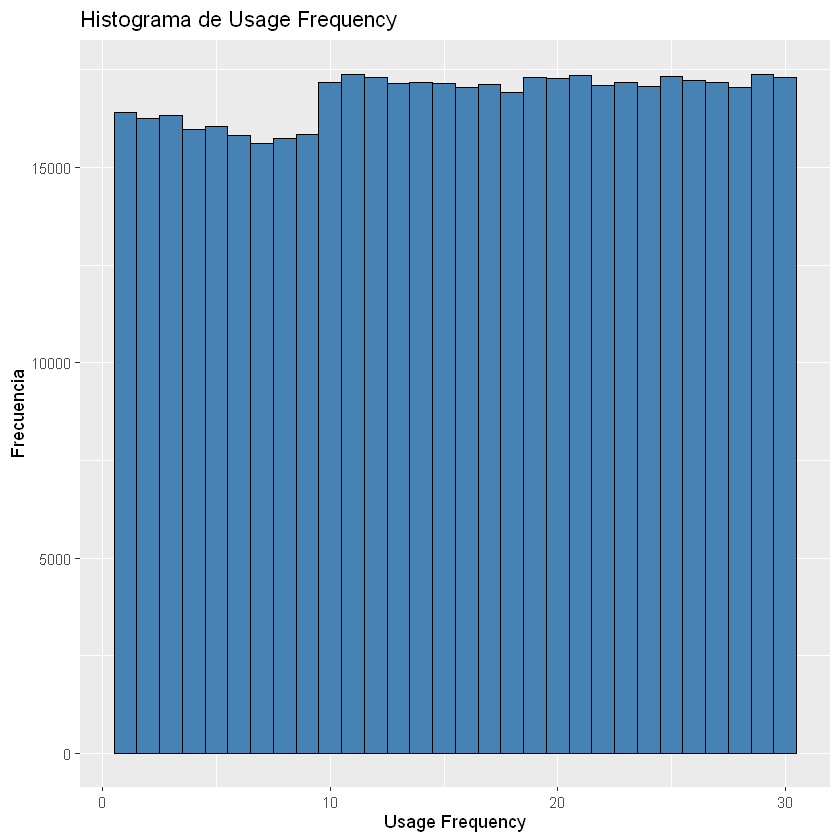

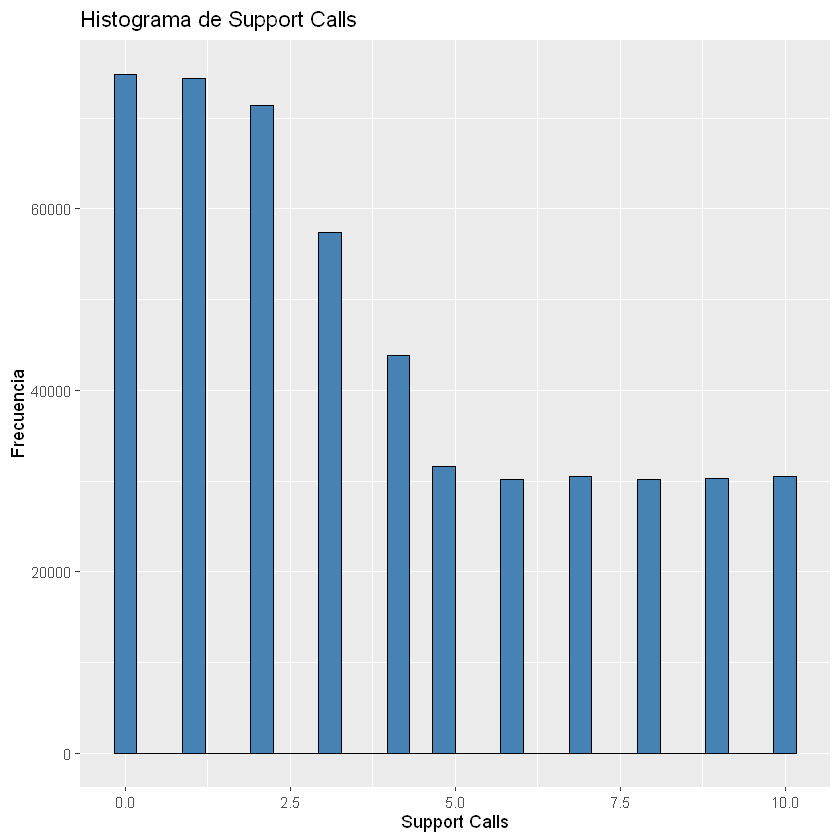

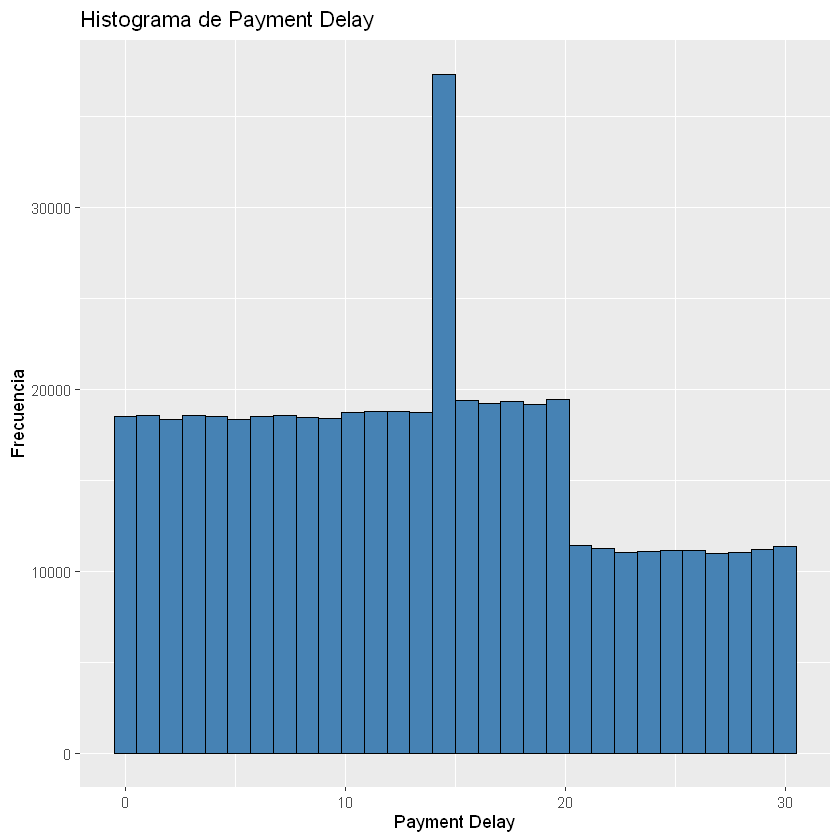

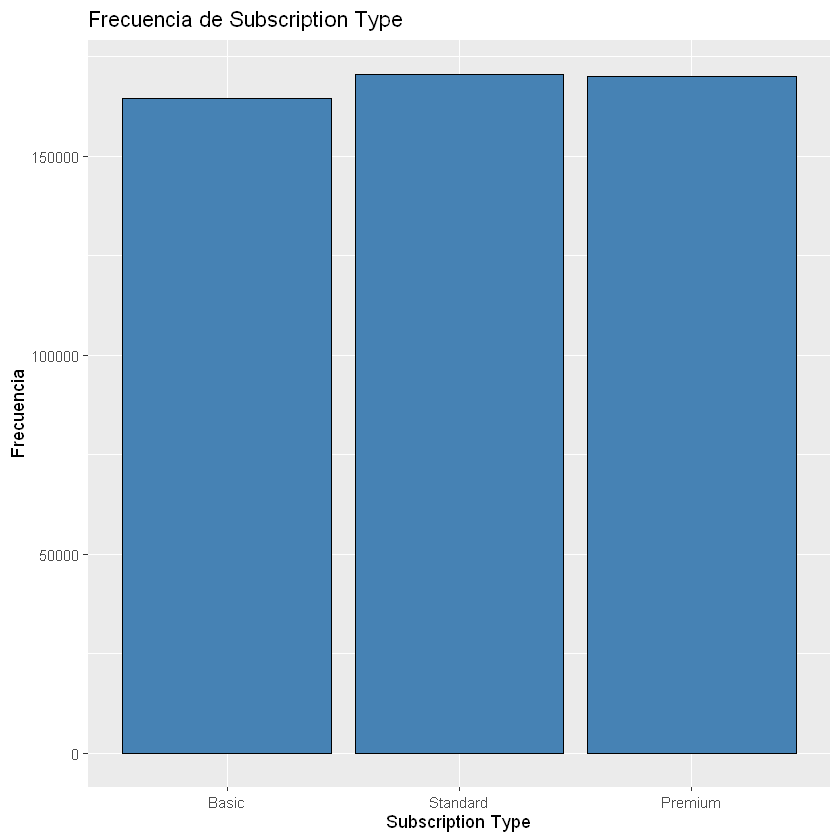

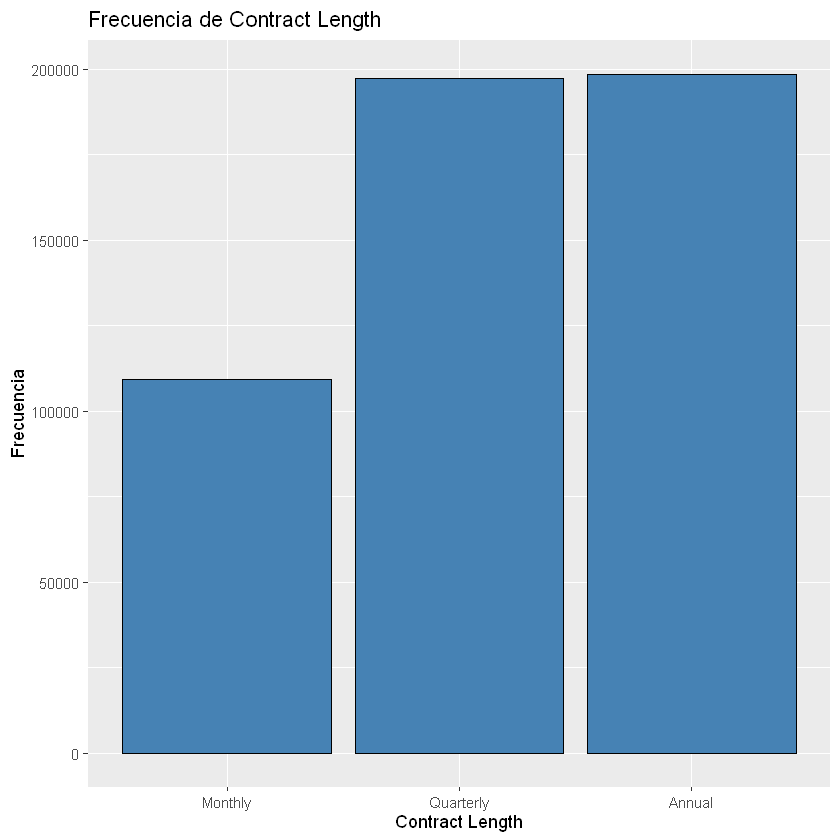

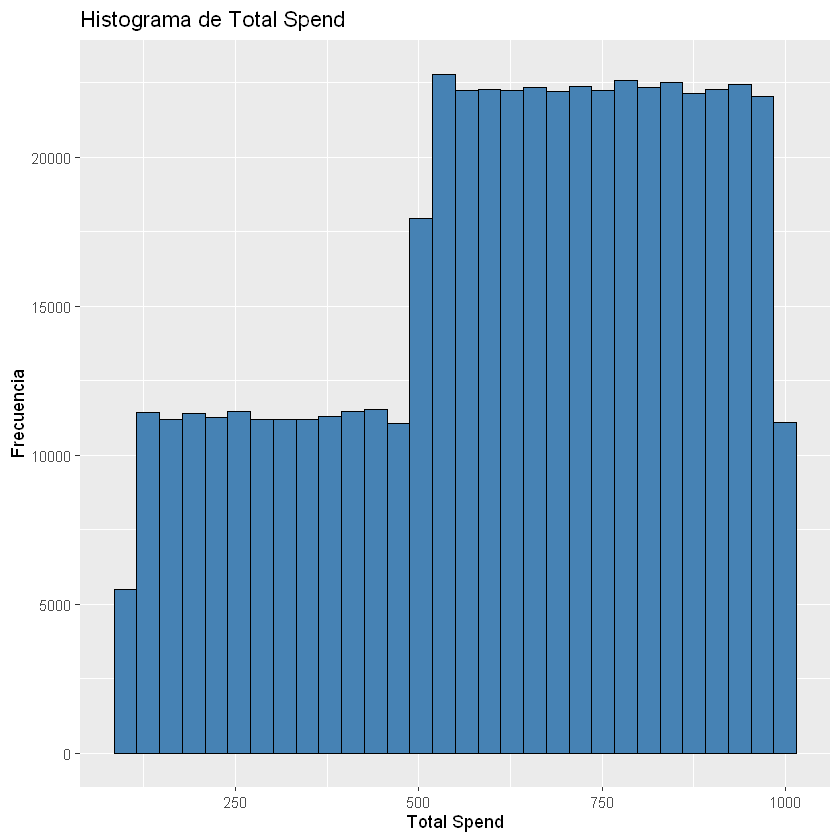

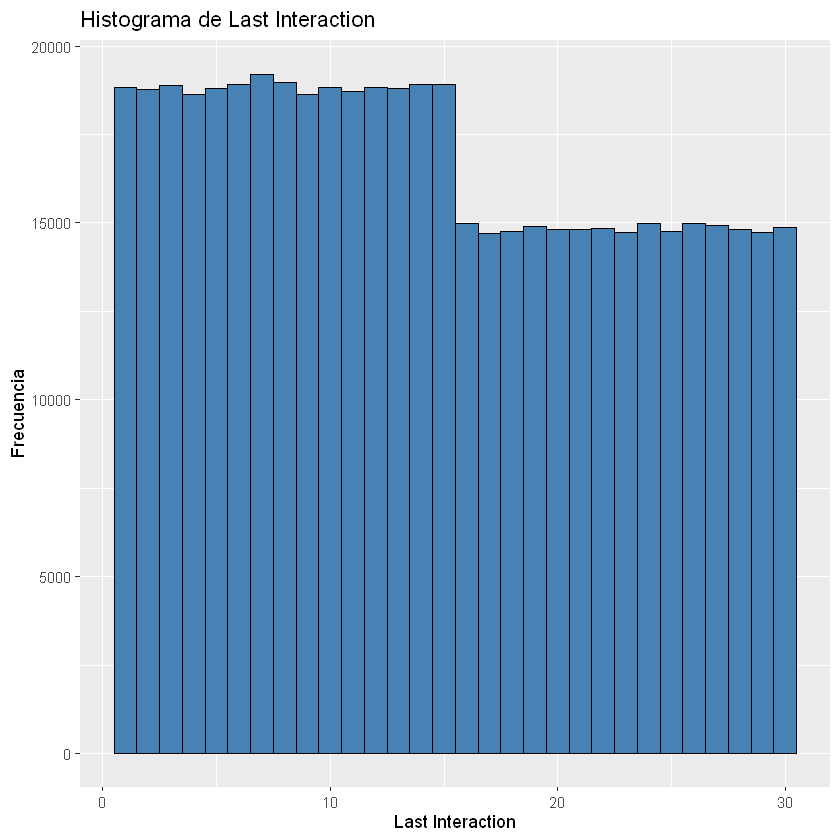

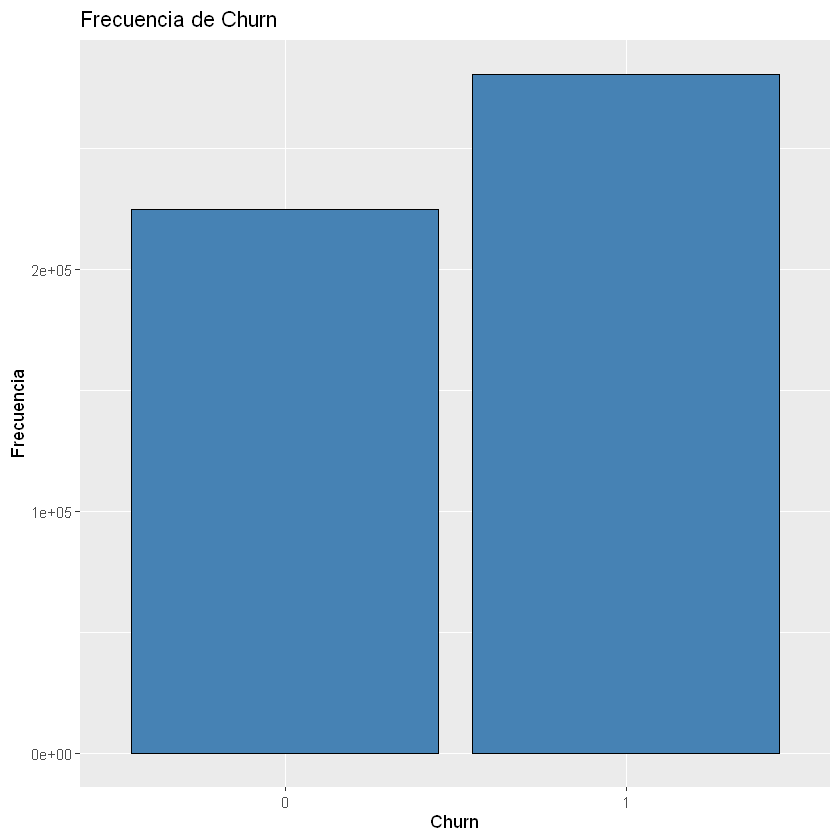

In [8]:
if (!require(tidyverse)) install.packages("tidyverse")
library(tidyverse)
if (!require(patchwork)) install.packages("patchwork")
library(patchwork)
ggplot(dfDatosLimpio, aes(x = Age)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Age", x = "Edad", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Gender)) + geom_bar(fill = "steelblue", colour = "black") + labs(title = "Histograma de Gender", x = "Género", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Tenure)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Tenure", x = "Tenure", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Usage.Frequency)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Usage Frequency", x = "Usage Frequency", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Support.Calls)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Support Calls", x = "Support Calls", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Payment.Delay)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Payment Delay", x = "Payment Delay", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Subscription.Type)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Basic", "Standard", "Premium")) + labs(title = "Frecuencia de Subscription Type", x = "Subscription Type", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Contract.Length)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Monthly", "Quarterly", "Annual")) + labs(title = "Frecuencia de Contract Length", x = "Contract Length", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Total.Spend)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Total Spend", x = "Total Spend", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Last.Interaction)) + geom_histogram(fill = "steelblue", bins = 30, colour = "black") + labs(title = "Histograma de Last Interaction", x = "Last Interaction", y = "Frecuencia")
ggplot(dfDatosLimpio, aes(x = Churn)) + geom_bar(fill = "steelblue", colour = "black") + labs(title = "Frecuencia de Churn", x = "Churn", y = "Frecuencia")


### Discretización de las variables numéricas

Los histogramas de variables numéricas con valores enteros y pocos valores distintos resultan poco informativos. Además, para estudiar cómo se relaciona cada variable con `Churn` y alimentar a modelos como Naive Bayes conviene trabajar con **tramos con significado propio**. Por ello discretizamos cada variable numérica en nuevas columnas `*_Dividido`, conservando las originales. Los umbrales se eligieron a partir de las distribuciones observadas:

| Variable | Tramos |
|---|---|
| `Age` | Joven (< 30), Adulto (30–59), Mayor (≥ 60) |
| `Tenure` | Menos de 20 (≤ 20), Entre 20 y 40, Más de 40 (≥ 40) |
| `Usage.Frequency` | Menos de 10, Entre 10 y 20, Más de 20 |
| `Support.Calls` | Menos de 2.5 (0–2), Entre 2.5 y 5 (3–5), Entre 5 y 7.5 (6–7), Más de 7.5 (8–10) |
| `Payment.Delay` | Menos de 10 (≤ 10), Entre 10 y 20, Más de 20 (≥ 20) |
| `Total.Spend` | Menos de 250 (≤ 250), Entre 250 y 500, Entre 500 y 750, Más de 750 (≥ 750) |
| `Last.Interaction` | Menos de 10, Entre 10 y 20, Más de 20 |

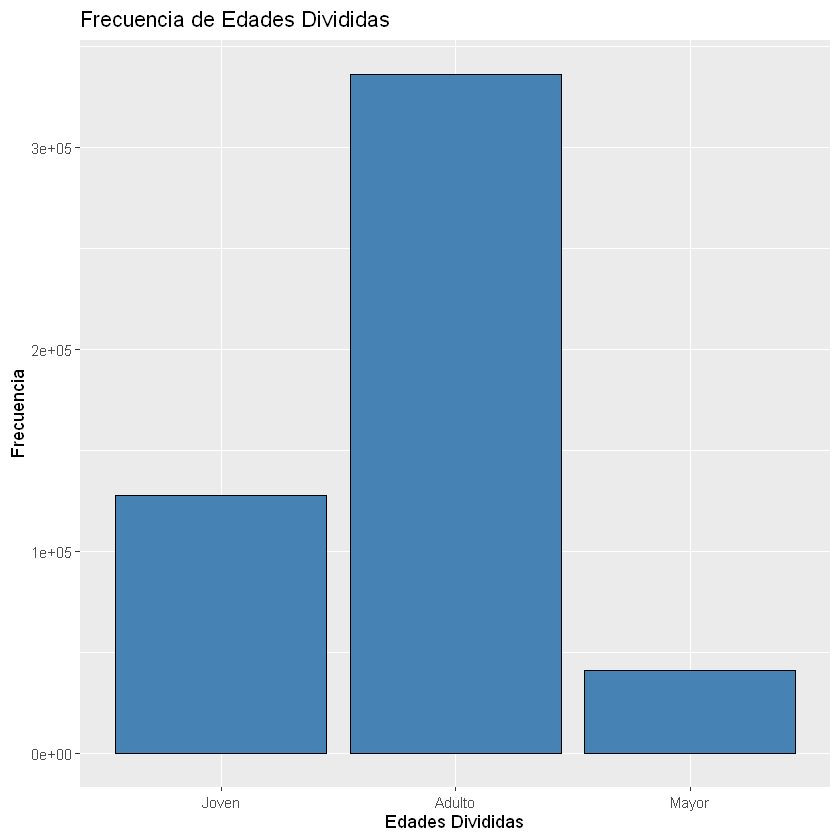

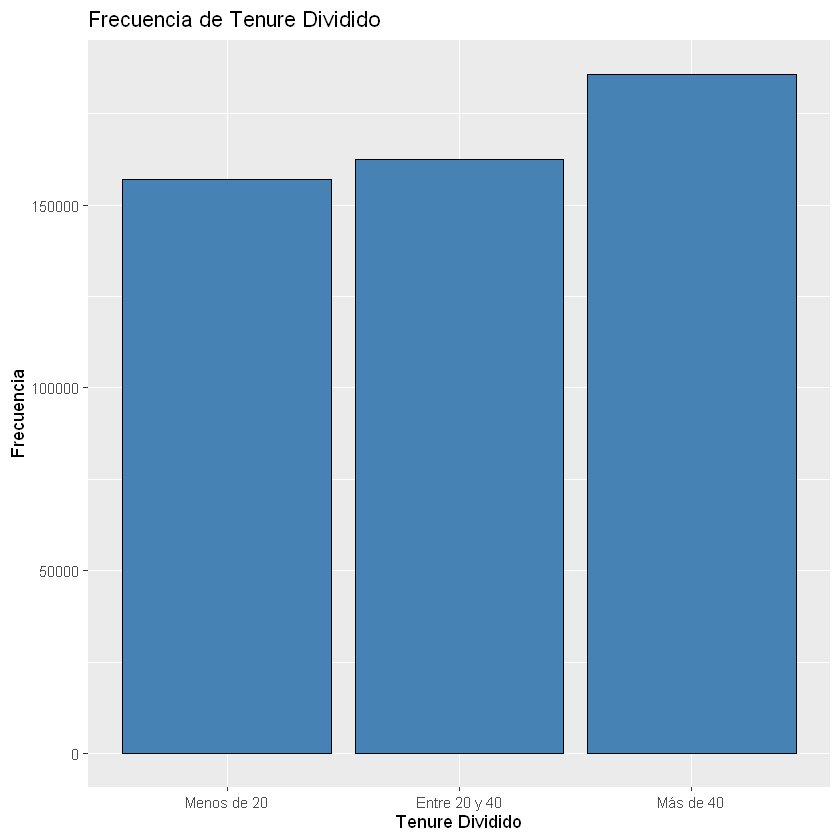

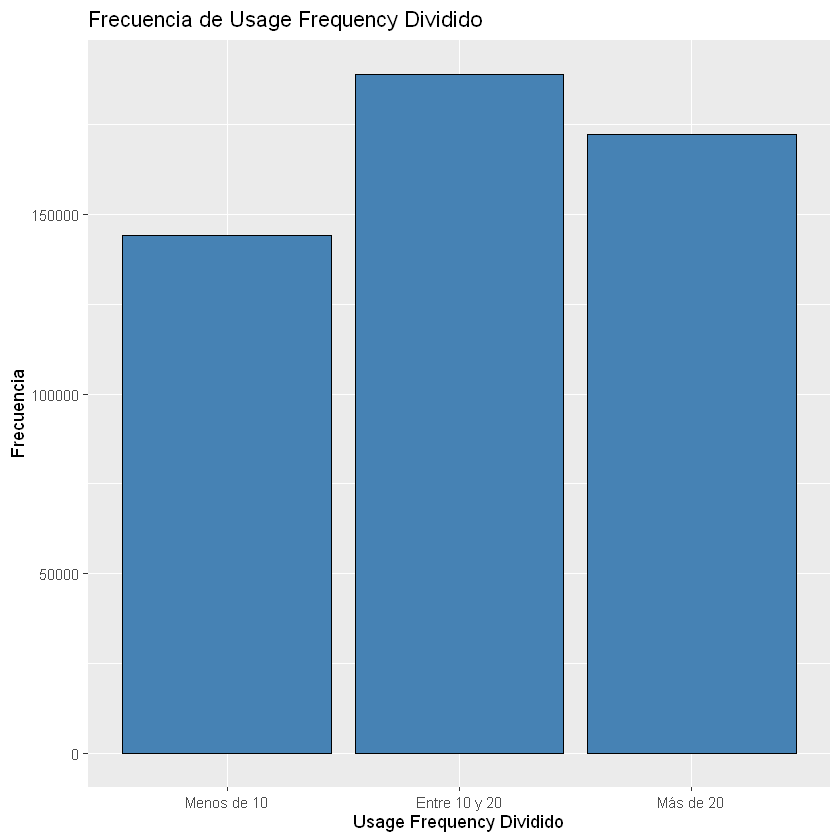

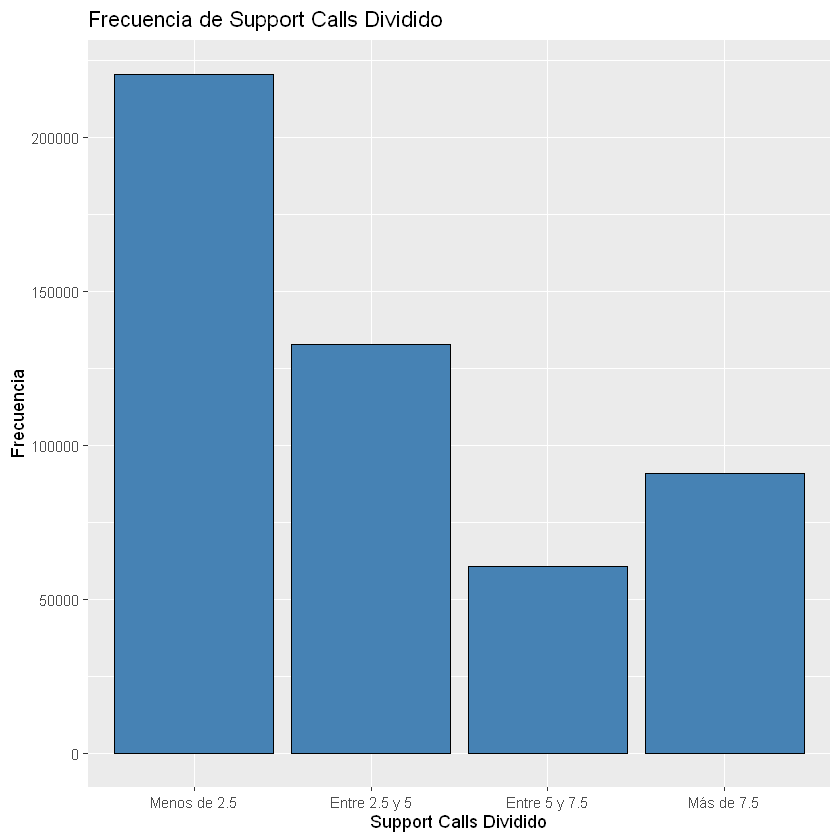

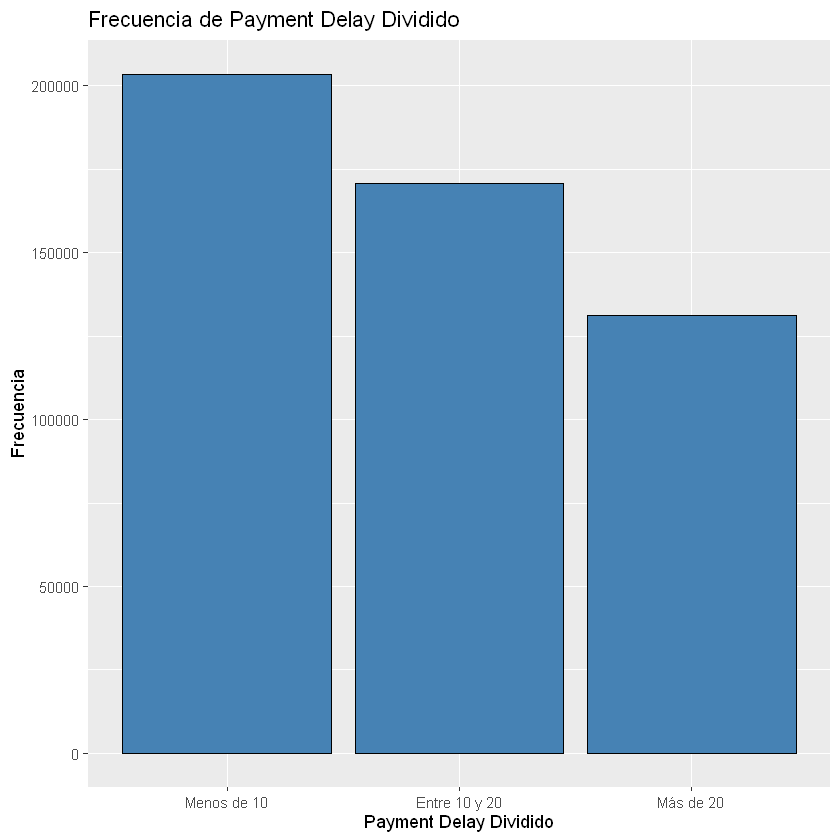

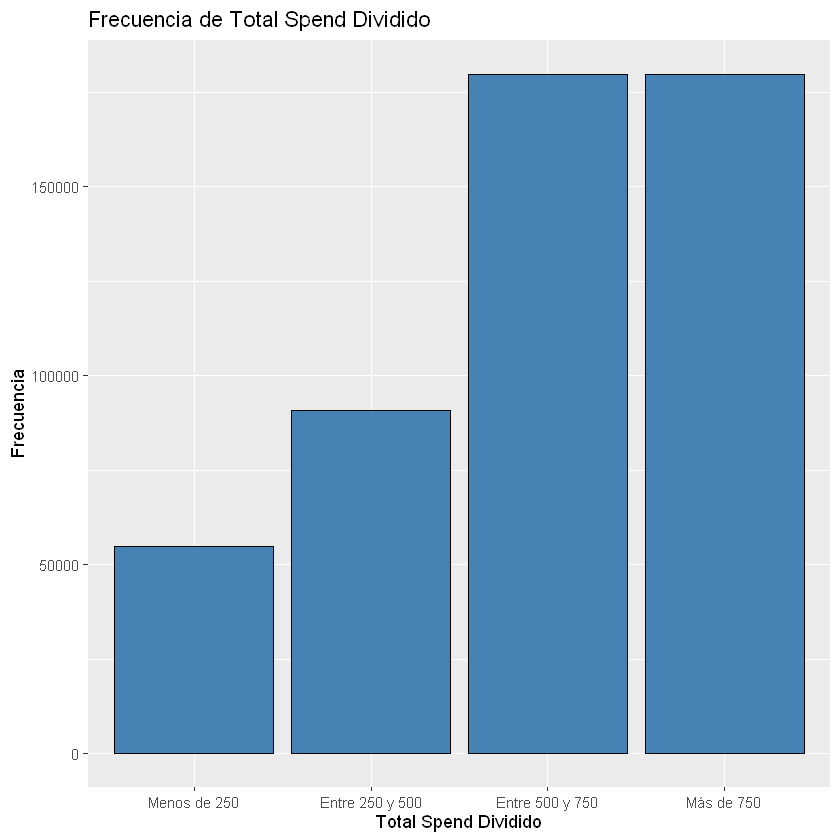

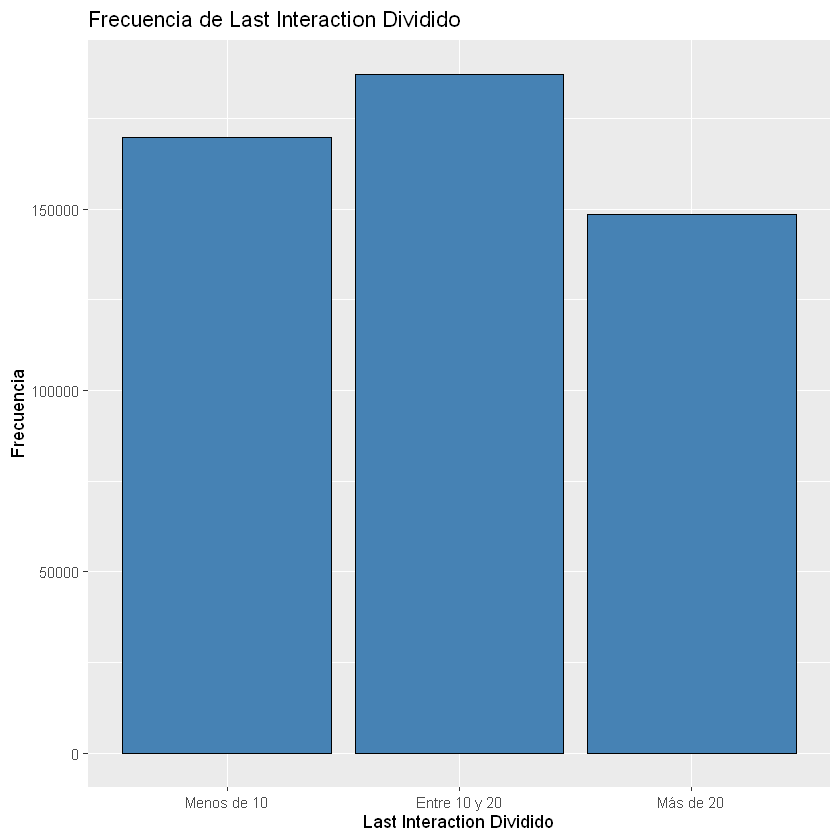

In [9]:
dfDatosLimpio$Age_Dividido <- ifelse(dfDatosLimpio$Age < 30, 'Joven', 
                                ifelse(dfDatosLimpio$Age >= 60, 'Mayor', 'Adulto'))
ggplot(dfDatosLimpio, aes(x = Age_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Joven", "Adulto", "Mayor")) + labs(title = "Frecuencia de Edades Divididas", x = "Edades Divididas", y = "Frecuencia")

dfDatosLimpio$Tenure_Dividido <- ifelse(dfDatosLimpio$Tenure <= 20, 'Menos de 20', 
                                ifelse(dfDatosLimpio$Tenure >= 40, 'Más de 40', 'Entre 20 y 40'))
ggplot(dfDatosLimpio, aes(x = Tenure_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Menos de 20", "Entre 20 y 40", "Más de 40")) + labs(title = "Frecuencia de Tenure Dividido", x = "Tenure Dividido", y = "Frecuencia")

dfDatosLimpio$UsageFrequency_Dividido <- ifelse(dfDatosLimpio$Usage.Frequency < 10, 'Menos de 10', 
                                ifelse(dfDatosLimpio$Usage.Frequency > 20, 'Más de 20', 'Entre 10 y 20'))
ggplot(dfDatosLimpio, aes(x = UsageFrequency_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Menos de 10", "Entre 10 y 20", "Más de 20")) + labs(title = "Frecuencia de Usage Frequency Dividido", x = "Usage Frequency Dividido", y = "Frecuencia")

dfDatosLimpio$SupportCalls_Dividido <- ifelse(dfDatosLimpio$Support.Calls <= 2.5, 'Menos de 2.5', 
                                ifelse(dfDatosLimpio$Support.Calls <= 5, 'Entre 2.5 y 5', 
                                ifelse(dfDatosLimpio$Support.Calls <= 7.5, 'Entre 5 y 7.5', 'Más de 7.5')))
ggplot(dfDatosLimpio, aes(x = SupportCalls_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Menos de 2.5", "Entre 2.5 y 5", "Entre 5 y 7.5", "Más de 7.5")) + labs(title = "Frecuencia de Support Calls Dividido", x = "Support Calls Dividido", y = "Frecuencia")

dfDatosLimpio$PaymentDelay_Dividido <- ifelse(dfDatosLimpio$Payment.Delay <= 10, 'Menos de 10', 
                                ifelse(dfDatosLimpio$Payment.Delay >= 20, 'Más de 20', 'Entre 10 y 20'))
ggplot(dfDatosLimpio, aes(x = PaymentDelay_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Menos de 10", "Entre 10 y 20", "Más de 20")) + labs(title = "Frecuencia de Payment Delay Dividido", x = "Payment Delay Dividido", y = "Frecuencia")

dfDatosLimpio$TotalSpend_Dividido <- ifelse(dfDatosLimpio$Total.Spend <= 250, 'Menos de 250', 
                                ifelse(dfDatosLimpio$Total.Spend >= 750, 'Más de 750', 
                                ifelse(dfDatosLimpio$Total.Spend >= 500, 'Entre 500 y 750', 'Entre 250 y 500')))
ggplot(dfDatosLimpio, aes(x = TotalSpend_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Menos de 250", "Entre 250 y 500", "Entre 500 y 750", "Más de 750")) + labs(title = "Frecuencia de Total Spend Dividido", x = "Total Spend Dividido", y = "Frecuencia")

dfDatosLimpio$LastInteraction_Dividido <- ifelse(dfDatosLimpio$Last.Interaction < 10, 'Menos de 10', 
                                ifelse(dfDatosLimpio$Last.Interaction > 20, 'Más de 20', 'Entre 10 y 20'))
ggplot(dfDatosLimpio, aes(x = LastInteraction_Dividido)) + geom_bar(fill = "steelblue", colour = "black") + scale_x_discrete(limits = c("Menos de 10", "Entre 10 y 20", "Más de 20")) + labs(title = "Frecuencia de Last Interaction Dividido", x = "Last Interaction Dividido", y = "Frecuencia")

### Relación de cada variable con el abandono

Para cada variable (en su versión discretizada, si era numérica) calculamos la tabla de contingencia frente a `Churn` y la normalizamos por filas con `prop.table(..., 1)`. Así, cada fila muestra la **probabilidad de abandono dentro de ese grupo**. Si una variable no influyera, todas sus filas rondarían la tasa global (≈ 55 %); cuanto más se alejen de ella, más informativa es la variable.

In [10]:
tabla_contingencia_Age <- table(dfDatosLimpio$Age_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_Age <- prop.table(tabla_contingencia_Age, 1)
print("Tabla de probabilidades Age")
print(tabla_probabilidades_Age)
print("")

tabla_contingencia_Gender <- table(dfDatosLimpio$Gender, dfDatosLimpio$Churn)
tabla_probabilidades_Gender <- prop.table(tabla_contingencia_Gender, 1)
print("Tabla de probabilidades Gender")
print(tabla_probabilidades_Gender)
print("")

tabla_contingencia_Tenure <- table(dfDatosLimpio$Tenure_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_Tenure <- prop.table(tabla_contingencia_Tenure, 1)
print("Tabla de probabilidades Tenure")
print(tabla_probabilidades_Tenure)
print("")

tabla_contingencia_UsageFrequency <- table(dfDatosLimpio$UsageFrequency_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_UsageFrequency <- prop.table(tabla_contingencia_UsageFrequency, 1)
print("Tabla de probabilidades Usage Frequency")
print(tabla_probabilidades_UsageFrequency)
print("")

tabla_contingencia_SupportCalls <- table(dfDatosLimpio$SupportCalls_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_SupportCalls <- prop.table(tabla_contingencia_SupportCalls, 1)
print("Tabla de probabilidades Support Calls")
print(tabla_probabilidades_SupportCalls)
print("")

tabla_contingencia_PaymentDelay <- table(dfDatosLimpio$PaymentDelay_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_PaymentDelay <- prop.table(tabla_contingencia_PaymentDelay, 1)
print("Tabla de probabilidades Payment Delay")
print(tabla_probabilidades_PaymentDelay)
print("")

tabla_contingencia_SubscriptionType <- table(dfDatosLimpio$Subscription.Type, dfDatosLimpio$Churn)
tabla_probabilidades_SubscriptionType <- prop.table(tabla_contingencia_SubscriptionType, 1)
print("Tabla de probabilidades Subscription Type")
print(tabla_probabilidades_SubscriptionType)
print("")

tabla_contingencia_ContractLength <- table(dfDatosLimpio$Contract.Length, dfDatosLimpio$Churn)
tabla_probabilidades_ContractLength <- prop.table(tabla_contingencia_ContractLength, 1)
print("Tabla de probabilidades Contract Length")
print(tabla_probabilidades_ContractLength)
print("")

tabla_contingencia_TotalSpend <- table(dfDatosLimpio$TotalSpend_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_TotalSpend <- prop.table(tabla_contingencia_TotalSpend, 1)
print("Tabla de probabilidades Total Spend")
print(tabla_probabilidades_TotalSpend)
print("")

tabla_contingencia_LastInteraction <- table(dfDatosLimpio$LastInteraction_Dividido, dfDatosLimpio$Churn)
tabla_probabilidades_LastInteraction <- prop.table(tabla_contingencia_LastInteraction, 1)
print("Tabla de probabilidades Last Interaction")
print(tabla_probabilidades_LastInteraction)

[1] "Tabla de probabilidades Age"
        
                 0         1
  Adulto 0.4820546 0.5179454
  Joven  0.4582710 0.5417290
  Mayor  0.0987960 0.9012040
[1] ""
[1] "Tabla de probabilidades Gender"
        
                 0         1
  Female 0.3510556 0.6489444
  Male   0.5200287 0.4799713
[1] ""
[1] "Tabla de probabilidades Tenure"
               
                        0         1
  Entre 20 y 40 0.4457845 0.5542155
  Más de 40     0.4558675 0.5441325
  Menos de 20   0.4306789 0.5693211
[1] ""
[1] "Tabla de probabilidades Usage Frequency"
               
                        0         1
  Entre 10 y 20 0.4657763 0.5342237
  Más de 20     0.4643127 0.5356873
  Menos de 10   0.3939480 0.6060520
[1] ""
[1] "Tabla de probabilidades Support Calls"
               
                         0          1
  Entre 2.5 y 5 0.43529058 0.56470942
  Entre 5 y 7.5 0.08468234 0.91531766
  Más de 7.5    0.08561474 0.91438526
  Menos de 2.5  0.69766578 0.30233422
[1] ""
[1] "Tabla de probab

### Patrones relevantes

Tomando como referencia la tasa global de abandono (≈ 55 %), los grupos con una probabilidad claramente superior son:

| Grupo | Probabilidad de abandono |
|---|---|
| Más de 5 llamadas a soporte | ≈ 91,5 % |
| Contrato mensual | 90,2 % |
| Clientes mayores (≥ 60 años) | 90,1 % |
| Gasto total inferior a 500 | ≈ 90 % |
| Retraso de pago superior a 20 | 87,4 % |
| Mujeres | 64,9 % |
| Última interacción de hace más de 20 | 63,8 % |
| Menos de 10 de frecuencia de uso | 60,6 % |

En cambio, `Subscription.Type` (55–57 % en los tres planes) y `Tenure` (54–57 %) apenas discriminan.

Varios de estos patrones son **saltos bruscos** (de un 40–50 % a un 90 %) al cruzar un umbral, lo que anticipa que los modelos basados en reglas, como el árbol de decisión, se desenvolverán bien. Conviene recordar que se trata de asociaciones estadísticas, no de relaciones causales.


## 3. Modelado y evaluación

### 3.1 Árbol de decisión base

Entrenamos un árbol de clasificación (`rpart`) con las 10 variables predictoras, usando las categóricas y las versiones discretizadas de las numéricas. Los datos se dividen en **70 % entrenamiento y 30 % prueba**, y todas las métricas se calculan sobre el conjunto de prueba, que el modelo no ha visto. Esta primera partición no fija semilla, por lo que las cifras pueden variar ligeramente entre ejecuciones; el resto de modelos sí la fijan.

Métricas utilizadas:

- **Accuracy:** proporción total de aciertos.
- **Recall (sensibilidad):** de los casos reales de una clase, qué proporción detecta el modelo.
- **F1-Score:** media armónica de la precisión y el recall; útil cuando interesa equilibrar ambos.

Cargando paquete requerido: lattice


Adjuntando el paquete: 'caret'


The following object is masked from 'package:purrr':

    lift




[1] "Matriz de confusión"
Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 55612  6028
         1 11302 78620
                                         
               Accuracy : 0.8857         
                 95% CI : (0.884, 0.8873)
    No Information Rate : 0.5585         
    P-Value [Acc > NIR] : < 2.2e-16      
                                         
                  Kappa : 0.7662         
                                         
 Mcnemar's Test P-Value : < 2.2e-16      
                                         
            Sensitivity : 0.8311         
            Specificity : 0.9288         
         Pos Pred Value : 0.9022         
         Neg Pred Value : 0.8743         
             Prevalence : 0.4415         
         Detection Rate : 0.3669         
   Detection Prevalence : 0.4067         
      Balanced Accuracy : 0.8799         
                                         
       'Positive' Class : 0              
            

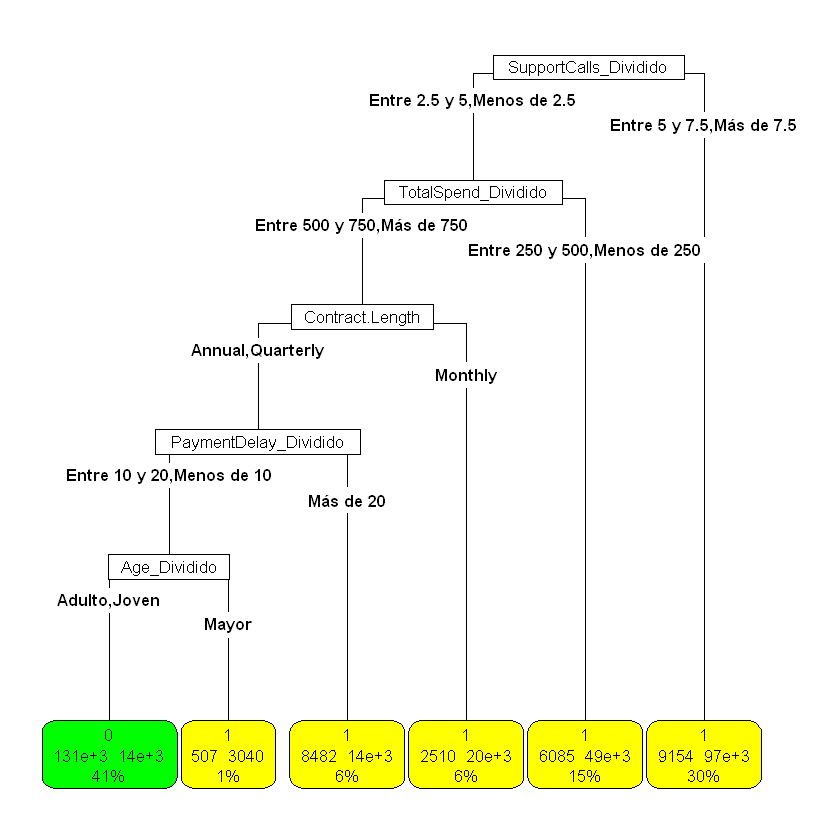

In [11]:
if (!require(rpart)) install.packages("rpart")
library(rpart)
if (!require(rpart.plot)) install.packages("rpart.plot")
library(rpart.plot)
if (!require(caret)) install.packages("caret")
library(caret)

train_index <- sample(1:nrow(dfDatosLimpio), 0.7 * nrow(dfDatosLimpio))
train_data <- dfDatosLimpio[train_index, ]
test_data <- dfDatosLimpio[-train_index, ]

model.rpart <- rpart(Churn ~ Age_Dividido + Gender + Tenure_Dividido + UsageFrequency_Dividido + SupportCalls_Dividido + PaymentDelay_Dividido + Subscription.Type + Contract.Length + TotalSpend_Dividido + LastInteraction_Dividido, data = train_data, method = "class")
rpart.plot(model.rpart, type = 5, extra = 101, box.palette = list("green", "yellow", "red"))
predicciones_arbol <- predict(model.rpart, test_data, type = "class")

test_data$Churn <- as.factor(test_data$Churn)

matriz_confusion_arbol <- confusionMatrix(predicciones_arbol, test_data$Churn)
print("Matriz de confusión")
print(matriz_confusion_arbol)

# Calcular Accuracy, Recall y F1-Score
accuracy <- matriz_confusion_arbol$overall["Accuracy"]  # Accuracy
recall <- matriz_confusion_arbol$byClass["Sensitivity"]  # Recall
precision <- matriz_confusion_arbol$byClass["Pos Pred Value"]  # Precision
f1_score <- 2 * (precision * recall) / (precision + recall)  # F1-Score

# Mostrar resultados
cat("Accuracy del modelo:", round(accuracy, 4), "\n")
cat("Recall (Sensibilidad):", round(recall, 4), "\n")
cat("F1-Score:", round(f1_score, 4), "\n")

**Resultados del árbol base.** Sobre el conjunto de prueba el árbol alcanza una *accuracy* del **88,6 %** (Kappa 0,77). Detecta correctamente el 83,1 % de los clientes que permanecen (recall de la clase `0`) y el 92,9 % de los que abandonan (*Specificity* de `caret`), con un F1-Score de 0,865 para la clase `0`. Para valorar la cifra: un modelo que predijera siempre «abandona» acertaría un 55,9 % (*No Information Rate*), así que el árbol aporta una mejora clara.

### 3.2 Reducción de dimensionalidad con PCA

Probamos si el **análisis de componentes principales (PCA)** simplifica el árbol sin perder rendimiento. Se proyectan los datos sobre componentes ortogonales y se entrena el árbol con las necesarias para explicar al menos el 90 % de la varianza. Como las variables tienen escalas muy distintas, se estandarizan previamente (`scale = TRUE`).

Una salvedad importante: el código separa las numéricas con `is.numeric` y las categóricas con `is.factor`, pero las categóricas están guardadas como texto y no como factores. Por tanto, **el PCA solo utiliza las 7 variables numéricas originales** y deja fuera `Gender`, `Subscription.Type` y `Contract.Length`.

Welcome to factoextra!

Want to learn more? See two factoextra-related books at https://www.datanovia.com/library/principal-component-methods

Cargando paquete requerido: FactoMineR



Importance of components:
                          PC1    PC2    PC3    PC4    PC5    PC6    PC7
Standard deviation     1.1999 1.0104 0.9896 0.9876 0.9727 0.9340 0.8752
Proportion of Variance 0.2057 0.1459 0.1399 0.1393 0.1352 0.1246 0.1094
Cumulative Proportion  0.2057 0.3515 0.4914 0.6308 0.7660 0.8906 1.0000

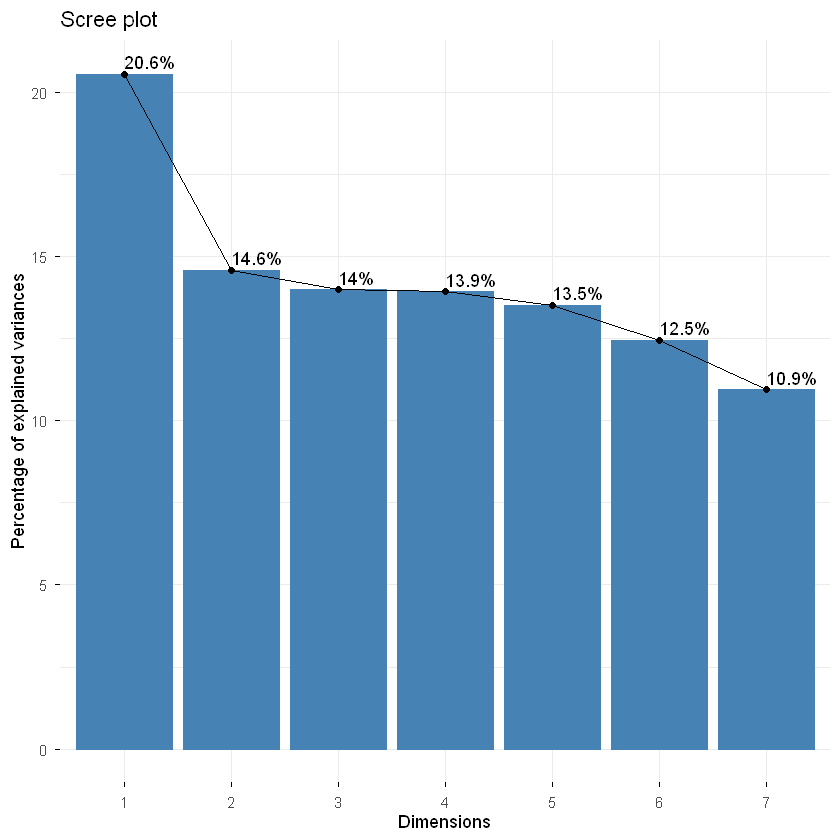

[1] "Matriz de confusión"
Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 52351 11326
         1 14672 73213
                                          
               Accuracy : 0.8285          
                 95% CI : (0.8266, 0.8304)
    No Information Rate : 0.5578          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.6505          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7811          
            Specificity : 0.8660          
         Pos Pred Value : 0.8221          
         Neg Pred Value : 0.8331          
             Prevalence : 0.4422          
         Detection Rate : 0.3454          
   Detection Prevalence : 0.4201          
      Balanced Accuracy : 0.8236          
                                          
       'Positive' Class : 0        

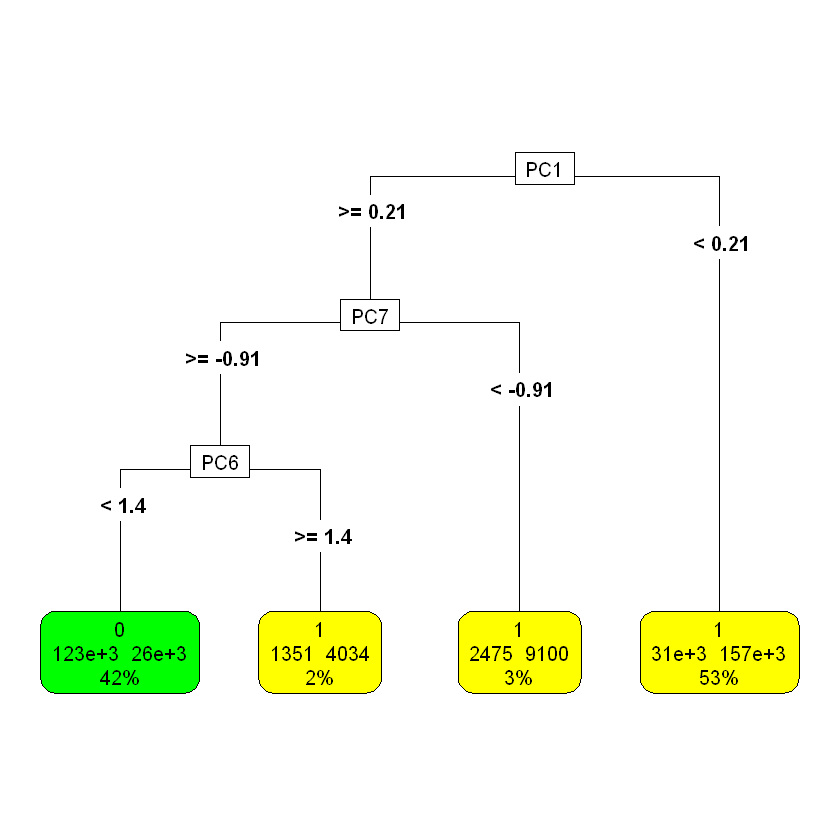

In [12]:
# Instalar y cargar librerías necesarias
if (!require(rpart)) install.packages("rpart")
library(rpart)
if (!require(rpart.plot)) install.packages("rpart.plot")
library(rpart.plot)
if (!require(caret)) install.packages("caret")
library(caret)
if (!require(factoextra)) install.packages("factoextra")
library(factoextra)
if (!require(FactoMineR)) install.packages("FactoMineR")
library(FactoMineR)

# Dividir los datos en conjunto de entrenamiento y prueba
set.seed(123)  # Fijar semilla para reproducibilidad
train_index <- sample(1:nrow(dfDatosLimpio), 0.7 * nrow(dfDatosLimpio))
train_data <- dfDatosLimpio[train_index, ]
test_data <- dfDatosLimpio[-train_index, ]

# Filtrar solo las columnas numéricas y convertir las categóricas en dummies
numerical_data <- train_data[, sapply(train_data, is.numeric)]  # Seleccionar solo las columnas numéricas
categorical_data <- train_data[, sapply(train_data, is.factor)] # Seleccionar columnas categóricas

# Convertir columnas categóricas a dummies
if (ncol(categorical_data) > 0) {
  categorical_dummies <- model.matrix(~ . - 1, data = categorical_data) # -1 para eliminar la columna de intercepción
  train_data_numeric <- cbind(numerical_data, categorical_dummies) # Combinar los datos numéricos con los dummies
} else {
  train_data_numeric <- numerical_data
}

# Aplicar PCA (excluyendo la variable objetivo Churn)
res.pca <- prcomp(train_data_numeric, scale = TRUE)  # train_data_numeric es ahora 100% numérico

# Mostrar resumen y Screeplot para elegir el número de componentes principales
summary(res.pca)
fviz_screeplot(res.pca, addlabels = TRUE)

# Determinar el número de componentes principales a usar
# Usar la regla de Kaiser (autovalores > 1) o elegir componentes que expliquen el 80-90% de la varianza
num_componentes <- which(cumsum(res.pca$sdev^2 / sum(res.pca$sdev^2)) >= 0.9)[1]  # 90% de la varianza

# Proyectar los conjuntos de entrenamiento y prueba a las nuevas dimensiones principales
train_pca <- as.data.frame(predict(res.pca, train_data_numeric)[, 1:num_componentes])
numerical_test_data <- test_data[, sapply(test_data, is.numeric)]  # Seleccionar solo las columnas numéricas
test_categorical_data <- test_data[, sapply(test_data, is.factor)] # Seleccionar columnas categóricas

if (ncol(test_categorical_data) > 0) {
  test_categorical_dummies <- model.matrix(~ . - 1, data = test_categorical_data) # -1 para eliminar la columna de intercepción
  test_data_numeric <- cbind(numerical_test_data, test_categorical_dummies) # Combinar los datos numéricos con los dummies
} else {
  test_data_numeric <- numerical_test_data
}

test_pca <- as.data.frame(predict(res.pca, test_data_numeric)[, 1:num_componentes])

# Agregar la variable objetivo (Churn) a los conjuntos de entrenamiento y prueba
train_pca$Churn <- train_data$Churn
test_pca$Churn <- test_data$Churn

# Entrenar el modelo rpart con los componentes principales seleccionados
model.rpart <- rpart(Churn ~ ., data = train_pca, method = "class")
rpart.plot(model.rpart, type = 5, extra = 101, box.palette = list("green", "yellow", "red"))

# Predecir en el conjunto de prueba
predicciones_arbol <- predict(model.rpart, test_pca, type = "class")

# Calcular matriz de confusión
matriz_confusion_arbol <- confusionMatrix(predicciones_arbol, as.factor(test_pca$Churn))
print("Matriz de confusión")
print(matriz_confusion_arbol)

# Calcular Accuracy, Recall y F1-Score
accuracy <- matriz_confusion_arbol$overall["Accuracy"]  # Accuracy
recall <- matriz_confusion_arbol$byClass["Sensitivity"]  # Recall
precision <- matriz_confusion_arbol$byClass["Pos Pred Value"]  # Precision
f1_score <- 2 * (precision * recall) / (precision + recall)  # F1-Score

# Mostrar resultados
cat("Accuracy del modelo:", round(accuracy, 4), "\n")
cat("Recall (Sensibilidad):", round(recall, 4), "\n")
cat("F1-Score:", round(f1_score, 4), "\n")

# Identificar las variables originales más influyentes en cada componente principal
loadings <- res.pca$rotation[, 1:num_componentes]  # Cargas (loadings) de las componentes

# Extraer las variables originales más importantes por componente
top_variables <- apply(loadings, 2, function(x) names(sort(abs(x), decreasing = TRUE)[1:3]))

# Mostrar relación entre PCX y variables originales
cat("Variables más influyentes por componente principal:\n")
for (i in 1:ncol(top_variables)) {
  cat("PC", i, "está influenciado por:", paste(top_variables[, i], collapse = ", "), "\n")
}


**Resultados del PCA.** Todas las métricas empeoran respecto al árbol base: la *accuracy* baja del 88,6 % al 82,9 %, el Kappa de 0,77 a 0,65, el recall de la clase `0` de 0,831 a 0,781 y el F1-Score de 0,865 a 0,801. Hay dos motivos que lo explican:

1. **No hay dimensionalidad que reducir.** La varianza se reparte casi por igual entre las 7 componentes (la primera explica solo el 20,6 %), señal de que las variables numéricas apenas están correlacionadas entre sí. Para alcanzar el 90 % de varianza hacen falta las 7 componentes (las 6 primeras suman el 89,1 %), de modo que el PCA no comprime nada.
2. **Se pierde información útil.** Se descartan las variables categóricas (entre ellas `Contract.Length`, una de las más determinantes) y, además, rotar los ejes hace que las divisiones del árbol dejen de ser umbrales sobre variables interpretables (p. ej. PC1 mezcla `Support.Calls`, `Total.Spend` y `Payment.Delay`).

**Conclusión:** el PCA no aporta valor en este problema, por lo que mantenemos las variables originales. Hay que matizar que la comparación no es exacta, ya que el árbol base se evaluó con una partición distinta (sin semilla fija).

### 3.3 Estudio de ablación sobre el árbol

El estudio de ablación consiste en **eliminar una variable cada vez**, reentrenar el modelo sin ella y medir cuánto cae la *accuracy* en el conjunto de prueba: cuanto mayor es la caída, más importante es esa variable. Se aplica a todas las variables disponibles (las originales y las versiones discretizadas; se excluye `CustomerID`). El resultado es un ranking de importancia que permite descartar las variables que no aportan.

Las tres celdas siguientes calculan la *accuracy* al eliminar cada variable, la representan en un gráfico y reentrenan el árbol final solo con las variables relevantes.


In [13]:
# Ensure required libraries are loaded
if (!require(rpart)) install.packages("rpart")
library(rpart)

# Function to evaluate ablation
evaluar_ablacion_arbol <- function(data_train, data_test, target, feature) {
    formula <- as.formula(
        paste(target, "~", paste(setdiff(names(data_train), c(target, feature, "CustomerID")), collapse = "+"))
    )
    
    modelo <- rpart(formula, data = data_train, method = "class")
    predicciones <- predict(modelo, data_test, type = "class")
    precision <- mean(predicciones == data_test[[target]])
    return(precision)
}

features <- setdiff(names(train_data), c("Churn", "CustomerID"))

# Perform ablation
resultados_ablacion_arbol <- sapply(features, function(feature) {
    evaluar_ablacion_arbol(train_data, test_data, "Churn", feature)
})

resultados_ablacion_arbol <- sort(resultados_ablacion_arbol, decreasing = TRUE)
print(resultados_ablacion_arbol)


                  Gender                   Tenure          Usage.Frequency 
               0.9201119                0.9201119                0.9201119 
       Subscription.Type         Last.Interaction             Age_Dividido 
               0.9201119                0.9201119                0.9201119 
         Tenure_Dividido  UsageFrequency_Dividido    SupportCalls_Dividido 
               0.9201119                0.9201119                0.9201119 
   PaymentDelay_Dividido      TotalSpend_Dividido LastInteraction_Dividido 
               0.9201119                0.9201119                0.9201119 
             Total.Spend            Support.Calls                      Age 
               0.9200855                0.9152888                0.9105185 
           Payment.Delay          Contract.Length 
               0.9035642                0.9027791 


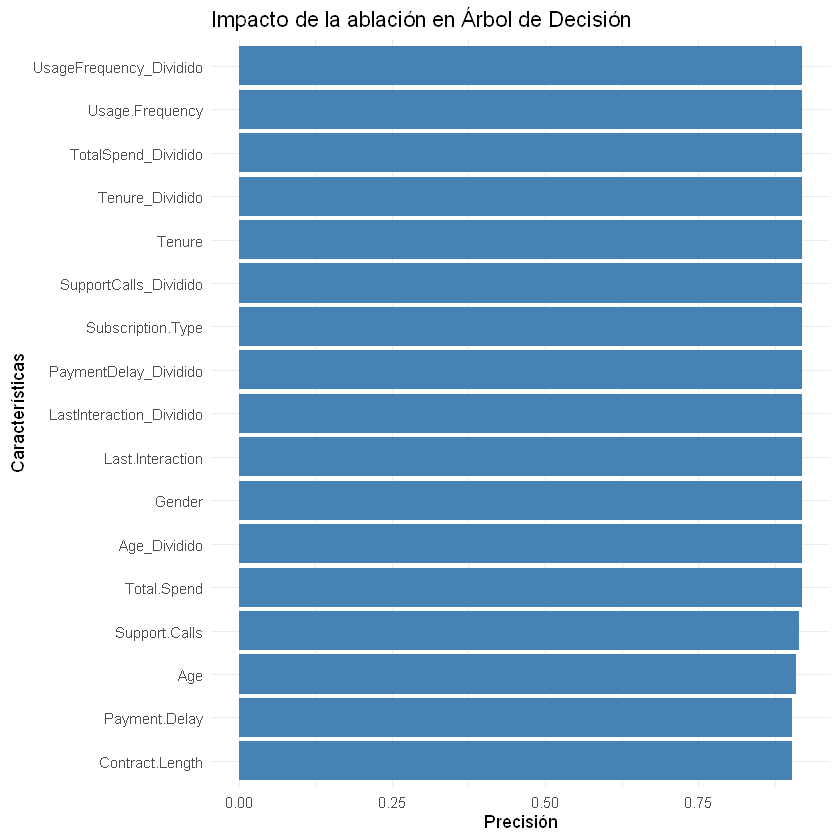

In [14]:

resultados_df <- data.frame(
  Feature = names(resultados_ablacion_arbol),
  Accuracy = resultados_ablacion_arbol
)

# Graficar
ggplot(resultados_df, aes(x = reorder(Feature, Accuracy), y = Accuracy)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  coord_flip() +
  labs(title = "Impacto de la ablación en Árbol de Decisión", x = "Características", y = "Precisión") +
  theme_minimal()


In [15]:
# Librerías necesarias
if (!require(rpart)) install.packages("rpart")
library(rpart)

if (!require(caret)) install.packages("caret")
library(caret)

# Variables menos importantes (con accuracy 0.9201119)
variables_a_excluir <- c(
  "CustomerID", "Gender", "Tenure", "Usage.Frequency", "Subscription.Type", 
  "Last.Interaction", "Age_Dividido", "Tenure_Dividido", 
  "UsageFrequency_Dividido", "SupportCalls_Dividido", 
  "PaymentDelay_Dividido", "TotalSpend_Dividido", "LastInteraction_Dividido"
)

# Crear una nueva fórmula excluyendo las variables irrelevantes
variables_restantes <- setdiff(names(train_data), c("Churn", variables_a_excluir))
nueva_formula <- as.formula(paste("Churn ~", paste(variables_restantes, collapse = " + ")))

# Entrenar el modelo
modelo_rpart <- rpart(nueva_formula, data = train_data, method = "class")

# Predecir en conjunto de prueba
predicciones_arbol <- predict(modelo_rpart, test_data, type = "class")

# Calcular la matriz de confusión y la accuracy
test_data$Churn <- as.factor(test_data$Churn)
matriz_confusion_arbol <- confusionMatrix(predicciones_arbol, test_data$Churn)

# Mostrar la precisión (Accuracy)
print("Matriz de Confusión:")
print(matriz_confusion_arbol)

print(paste("Accuracy del modelo sin variables irrelevantes:", 
            round(matriz_confusion_arbol$overall['Accuracy'], 4)))

[1] "Matriz de Confusión:"
Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 57799  2884
         1  9224 81655
                                          
               Accuracy : 0.9201          
                 95% CI : (0.9187, 0.9215)
    No Information Rate : 0.5578          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.8365          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.8624          
            Specificity : 0.9659          
         Pos Pred Value : 0.9525          
         Neg Pred Value : 0.8985          
             Prevalence : 0.4422          
         Detection Rate : 0.3814          
   Detection Prevalence : 0.4004          
      Balanced Accuracy : 0.9141          
                                          
       'Positive' Class : 0       

**Resultados de la ablación en el árbol**

- Eliminar `Gender`, `Tenure`, `Usage.Frequency`, `Subscription.Type`, `Last.Interaction` o cualquiera de las versiones discretizadas deja la *accuracy* **intacta (92,01 %)**: no aportan información al árbol. `Total.Spend` tampoco cambia apreciablemente (92,009 %).
- Las caídas aparecen al eliminar `Contract.Length` (90,28 %), `Payment.Delay` (90,36 %), `Age` (91,05 %) y `Support.Calls` (91,53 %).
- El árbol final se entrena solo con las 5 variables restantes (`Age`, `Support.Calls`, `Payment.Delay`, `Contract.Length` y `Total.Spend`) y obtiene una *accuracy* del **92,0 %**, Kappa 0,84, un recall de 0,862 para la clase `0`, una detección de abandonos del **96,6 %** (*Specificity*) y un F1-Score de 0,905 (clase `0`). Supone una mejora de unos 3,4 puntos sobre el árbol base y un modelo más sencillo (5 variables frente a 17 candidatas).

**Matices a tener en cuenta**

- **Variables redundantes:** al coexistir `Support.Calls` y `SupportCalls_Dividido` (y lo mismo con el resto), eliminar solo una de las dos apenas penaliza al modelo, porque la otra transmite casi la misma información. La ablación individual infravalora, por tanto, las variables duplicadas; por eso `Support.Calls` parece menos importante aquí que en Naive Bayes y en la regresión logística.
- **Origen de la mejora:** descartar las variables irrelevantes no cambia la *accuracy*, así que es probable que gran parte de la mejora frente al árbol base se deba a que este árbol puede usar las variables numéricas **sin discretizar**, que conservan más información. El estudio de ablación aporta, sobre todo, simplicidad e interpretabilidad.
- **Posible optimismo:** las variables se han seleccionado con el mismo conjunto de prueba con el que se evalúa el modelo, por lo que la cifra final es algo optimista. Lo ideal sería seleccionar con un conjunto de validación independiente o con validación cruzada.

### 3.4 Naive Bayes

Naive Bayes aplica el teorema de Bayes asumiendo que las variables son independientes entre sí una vez conocida la clase. Es muy rápido y funciona especialmente bien con variables categóricas, por lo que se entrena con las versiones discretizadas. Se usa una partición **estratificada 80/20** (`createDataPartition`, semilla 123) y **validación cruzada de 10 pliegues** para escoger la configuración. La validación cruzada compara dos variantes: la versión sin estimación kernel (`usekernel = FALSE`) alcanza un 85,5 % de *accuracy* frente al 64,5 % de la versión con kernel, por lo que se selecciona la primera.

In [16]:
# Instalación de paquetes si no están ya instalados
if (!require(naivebayes)) install.packages("naivebayes")
if (!require(caret)) install.packages("caret")
library(naivebayes)
library(caret)

# Factorizamos todos los datos
dfDatosLimpio$Churn <- as.factor(dfDatosLimpio$Churn)

# Dividir los datos en conjunto de entrenamiento y prueba (si aún no se ha hecho)
set.seed(123) # Para reproducibilidad
index <- createDataPartition(dfDatosLimpio$Churn, p = 0.8, list = FALSE)
train_data1 <- dfDatosLimpio[index, ]
test_data1 <- dfDatosLimpio[-index, ]

# Configurar la validación cruzada (10-fold cross-validation)
control <- trainControl(method = "cv", number = 10)

# Entrenar el modelo con validación cruzada
modelo.nb <- train(
  Churn ~ Age_Dividido + Gender + Tenure_Dividido + UsageFrequency_Dividido + 
    SupportCalls_Dividido + PaymentDelay_Dividido + Subscription.Type + 
    Contract.Length + TotalSpend_Dividido + LastInteraction_Dividido, 
  data = train_data1, 
  method = "naive_bayes", 
  trControl = control
)

# Ver los resultados de la validación cruzada
print(modelo.nb)

# Predecir en el conjunto de prueba
predicciones_nb <- predict(modelo.nb, test_data1)

# Generar la matriz de confusión
matriz_confusion_nb <- confusionMatrix(predicciones_nb, test_data1$Churn)
print("Matriz de confusión")
print(matriz_confusion_nb)

# Calcular Accuracy, Recall y F1-Score
accuracy <- matriz_confusion_nb$overall["Accuracy"]  # Accuracy
recall <- matriz_confusion_nb$byClass["Sensitivity"]  # Recall
precision <- matriz_confusion_nb$byClass["Pos Pred Value"]  # Precision
f1_score <- 2 * (precision * recall) / (precision + recall)  # F1-Score

# Mostrar resultados
cat("Accuracy del modelo:", round(accuracy, 4), "\n")
cat("Recall (Sensibilidad):", round(recall, 4), "\n")
cat("F1-Score:", round(f1_score, 4), "\n")


naivebayes 1.0.0 loaded

For more information please visit: 

https://majkamichal.github.io/naivebayes/



Naive Bayes 

404166 samples
    10 predictor
     2 classes: '0', '1' 

No pre-processing
Resampling: Cross-Validated (10 fold) 
Summary of sample sizes: 363750, 363749, 363750, 363750, 363749, 363749, ... 
Resampling results across tuning parameters:

  usekernel  Accuracy   Kappa    
  FALSE      0.8552996  0.7095552
   TRUE      0.6451260  0.3299747

Tuning parameter 'laplace' was held constant at a value of 0
Tuning
 parameter 'adjust' was held constant at a value of 1
Accuracy was used to select the optimal model using the largest value.
The final values used for the model were laplace = 0, usekernel = FALSE
 and adjust = 1.
[1] "Matriz de confusión"
Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 39721  9243
         1  5221 46855
                                         
               Accuracy : 0.8568         
                 95% CI : (0.8547, 0.859)
    No Information Rate : 0.5552         
    P-Value [Acc > NIR] : < 2.2e-16      
   

In [17]:
if (!require(e1071)) install.packages("e1071")
library(e1071)

# Función para evaluar impacto de ablación en Naive Bayes
evaluar_ablacion_nb <- function(data_train, data_test, target, feature) {
  # Crear fórmula sin la característica a eliminar
  formula <- as.formula(
    paste(target, "~", paste(setdiff(names(data_train), c(target, feature)), collapse = "+"))
  )
  
  # Ajustar modelo
  modelo <- naiveBayes(formula, data = data_train)
  
  # Predecir en conjunto de prueba
  predicciones <- predict(modelo, data_test)
  
  # Calcular precisión
  precision <- mean(predicciones == data_test[[target]])
  return(precision)
}

# Realizar ablación
resultados_ablacion_nb <- sapply(features, function(feature) {
  evaluar_ablacion_nb(train_data1, test_data1, "Churn", feature)
})

# Ordenar y mostrar resultados
resultados_ablacion_nb <- sort(resultados_ablacion_nb, decreasing = TRUE)
print(resultados_ablacion_nb)


Cargando paquete requerido: e1071


Adjuntando el paquete: 'e1071'


The following object is masked from 'package:ggplot2':

    element




         Tenure_Dividido LastInteraction_Dividido  UsageFrequency_Dividido 
               0.8701504                0.8700713                0.8700614 
                  Tenure          Usage.Frequency        Subscription.Type 
               0.8700119                0.8699921                0.8699426 
        Last.Interaction                   Gender             Age_Dividido 
               0.8697842                0.8684679                0.8670823 
   SupportCalls_Dividido                      Age    PaymentDelay_Dividido 
               0.8666766                0.8652514                0.8627870 
           Payment.Delay          Contract.Length              Total.Spend 
               0.8613025                0.8597486                0.8589173 
     TotalSpend_Dividido            Support.Calls 
               0.8584917                0.8516429 


**Resultados de Naive Bayes.** En el conjunto de prueba obtiene una *accuracy* del **85,7 %** (Kappa 0,71), un recall de 0,884 para la clase `0`, una detección de abandonos del 83,5 % (*Specificity*) y un F1-Score de 0,846. Su rendimiento está **más equilibrado entre ambas clases** que el del árbol base (que detecta mucho mejor los abandonos que las permanencias), aunque reconoce algo mejor a los clientes que permanecen que a los que se van y su *accuracy* global es inferior (85,7 % frente a 88,6 %).

**Ablación en Naive Bayes.** Se repite el estudio con `e1071::naiveBayes` usando todas las variables disponibles (originales y discretizadas), por lo que las cifras absolutas no son comparables con el 85,7 % anterior; lo relevante es el ranking. La mayor caída se produce al eliminar `Support.Calls` (85,2 %), seguida de `Total.Spend` y `TotalSpend_Dividido` (≈ 85,8–85,9 %), `Contract.Length` (86,0 %) y `Payment.Delay` (86,1–86,3 %). Las variables cuya eliminación menos afecta (`Tenure`, `Usage.Frequency`, `Subscription.Type`, `Last.Interaction`) se quedan en torno al 87,0 %. Con este método, la variable más influyente es de nuevo el **número de llamadas a soporte**.

### 3.5 Regresión logística (modelo lineal)

La regresión logística modela la probabilidad de abandono como función de una combinación lineal de las variables, lo que la hace muy interpretable. Se entrena con las **variables originales sin discretizar** (la copia `dfDatosLineal`); las categóricas se codifican automáticamente como variables ficticias (*dummies*) respecto a una categoría de referencia (`Female`, `Basic` y `Annual`). `Churn` se convierte a 0/1 para ajustar `glm(..., family = binomial)`, con una partición estratificada **70/30** (semilla 42), y se clasifica como abandono a los clientes con probabilidad superior a 0,5.

In [18]:
# Instalar dplyr si no está instalado
if (!require(dplyr)) install.packages("dplyr")

# Cargar librerías necesarias
library(dplyr)
library(caret)

# Convertir 'Churn' a variable numérica binaria (0 y 1) en la copia
dfDatosLineal$Churn <- as.integer(dfDatosLineal$Churn)

# Verificar las clases de Churn
unique(dfDatosLineal$Churn)

# Dividir los datos en entrenamiento y prueba (70% - 30%)
set.seed(42)
trainIndex <- createDataPartition(dfDatosLineal$Churn, p = 0.7, list = FALSE)
trainData <- dfDatosLineal[trainIndex, ]
testData  <- dfDatosLineal[-trainIndex, ]

# Crear copias de las variables para evitar cambios externos
trainDataCopy <- trainData
testDataCopy  <- testData

# Entrenar el modelo de Regresión Logística usando la copia
modelo_logit <- glm(Churn ~ ., data = trainDataCopy %>% select(-CustomerID), family = binomial)

# Resumen del modelo
summary(modelo_logit)

# Realizar predicciones en el conjunto de prueba
predicciones <- predict(modelo_logit, newdata = testDataCopy, type = "response")
predicted_class <- ifelse(predicciones > 0.5, 1, 0)

# Métricas de evaluación
confusion <- confusionMatrix(as.factor(predicted_class), as.factor(testDataCopy$Churn))
print(confusion)

# Matriz de Confusión
print("Matriz de Confusión:")
print(table(Predicho = predicted_class, Real = testDataCopy$Churn))

# Calcular precisión (Precision), sensibilidad (Recall) y F1-Score
precision <- confusion$byClass["Pos Pred Value"]  # Precisión
recall <- confusion$byClass["Sensitivity"]        # Sensibilidad (Recall)
f1_score <- 2 * (precision * recall) / (precision + recall)  # F1-Score

# Mostrar resultados
accuracy <- confusion$overall["Accuracy"]  # Accuracy
cat("Accuracy del modelo:", accuracy, "\n")
cat("Recall (Sensibilidad):", recall, "\n")
cat("F1-Score:", f1_score, "\n")


[1] 1 0


Call:
glm(formula = Churn ~ ., family = binomial, data = trainDataCopy %>% 
    select(-CustomerID))

Coefficients:
                            Estimate Std. Error  z value Pr(>|z|)    
(Intercept)               -1.292e+00  2.929e-02  -44.123  < 2e-16 ***
Age                        2.309e-02  3.964e-04   58.237  < 2e-16 ***
GenderMale                -7.313e-01  9.889e-03  -73.947  < 2e-16 ***
Tenure                    -9.189e-04  2.786e-04   -3.298 0.000974 ***
Usage.Frequency           -1.332e-02  5.580e-04  -23.880  < 2e-16 ***
Support.Calls              4.079e-01  1.899e-03  214.782  < 2e-16 ***
Payment.Delay              8.433e-02  6.217e-04  135.644  < 2e-16 ***
Subscription.TypePremium  -7.213e-02  1.179e-02   -6.118 9.50e-10 ***
Subscription.TypeStandard -6.928e-02  1.179e-02   -5.876 4.21e-09 ***
Contract.LengthMonthly     2.123e+00  1.574e-02  134.874  < 2e-16 ***
Contract.LengthQuarterly  -7.829e-03  1.022e-02   -0.766 0.443430    
Total.Spend               -3.149e-03  2.173

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 57045 12872
         1 10304 71340
                                          
               Accuracy : 0.8471          
                 95% CI : (0.8453, 0.8489)
    No Information Rate : 0.5556          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.6915          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.8470          
            Specificity : 0.8471          
         Pos Pred Value : 0.8159          
         Neg Pred Value : 0.8738          
             Prevalence : 0.4444          
         Detection Rate : 0.3764          
   Detection Prevalence : 0.4613          
      Balanced Accuracy : 0.8471          
                                          
       'Positive' Class : 0               
                  

In [19]:
evaluar_modelo <- function(variables) {
  # Construir la fórmula con las variables seleccionadas
  formula <- as.formula(paste("Churn ~", paste(variables, collapse = " + ")))
  
  # Manejar errores si el modelo no se ajusta correctamente
  tryCatch({
    # Entrenar el modelo
    modelo <- glm(formula, data = trainDataCopy, family = binomial)
    
    # Predicciones
    predicciones <- predict(modelo, newdata = testDataCopy, type = "response")
    predicted_class <- ifelse(predicciones > 0.5, 1, 0)
    
    # Calcular métricas
    confusion <- confusionMatrix(as.factor(predicted_class), as.factor(testDataCopy$Churn))
    accuracy <- confusion$overall["Accuracy"]
    recall <- confusion$byClass["Sensitivity"]
    
    return(c(accuracy = as.numeric(accuracy), recall = as.numeric(recall)))
    
  }, error = function(e) {
    # Si hay error, devuelve NA
    return(c(accuracy = NA, recall = NA))
  })
}

# Crear un dataframe vacío para guardar los resultados
resultados_ablacion <- data.frame(Variable = character(), Accuracy = numeric(), Recall = numeric(), stringsAsFactors = FALSE)

# Lista de variables originales (sin CustomerID y Churn)
variables_totales <- colnames(trainDataCopy %>% select(-CustomerID, -Churn))

# Bucle para evaluar el modelo sin cada variable
for (var in variables_totales) {
  # Eliminar la variable actual
  variables_restantes <- setdiff(variables_totales, var)
  
  # Evaluar el modelo
  metricas <- evaluar_modelo(variables_restantes)  # Llama a la función corregida
  
  # Manejo de NAs para evitar interrupciones
  if (any(is.na(metricas))) {
    metricas[is.na(metricas)] <- 0
  }
  
  # Guardar resultados
  resultados_ablacion <- rbind(resultados_ablacion, 
                               data.frame(Variable = var, 
                                          Accuracy = round(metricas["accuracy"], 6),
                                          Recall = round(metricas["recall"], 6)))
}

# Ordenar resultados por Accuracy en orden descendente
resultados_ablacion <- resultados_ablacion[order(-resultados_ablacion$Accuracy), ]

# Mostrar los resultados finales
print("Resultados del Estudio de Ablación (por variable eliminada):")
print(resultados_ablacion)


[1] "Resultados del Estudio de Ablación (por variable eliminada):"
                   Variable Accuracy   Recall
accuracy                Age 0.847329 0.851252
accuracy6 Subscription.Type 0.846973 0.846961
accuracy2            Tenure 0.846966 0.847095
accuracy3   Usage.Frequency 0.846709 0.846635
accuracy9  Last.Interaction 0.844340 0.844586
accuracy1            Gender 0.843891 0.845521
accuracy5     Payment.Delay 0.838923 0.844912
accuracy8       Total.Spend 0.825186 0.829322
accuracy7   Contract.Length 0.819175 0.812573
accuracy4     Support.Calls 0.791008 0.790168


**Resultados de la regresión logística.** Obtiene una *accuracy* del **84,7 %** (Kappa 0,69), con un recall de 0,847 para la clase `0`, una detección de abandonos del 84,7 % (*Specificity*) y un F1-Score de 0,831. Es el modelo con menor rendimiento, algo esperable: asume relaciones lineales y varias variables (edad, gasto, llamadas) actúan más bien por umbrales.

**Interpretación de los coeficientes.** Al exponenciar un coeficiente se obtiene el factor por el que se multiplican las probabilidades (*odds*) de abandono:

| Variable | Coeficiente | Efecto sobre los *odds* de abandono |
|---|---|---|
| `Contract.Length` = Monthly (frente a Annual) | +2,123 | × 8,4 |
| `Support.Calls` | +0,408 por llamada | × 1,50 por cada llamada adicional |
| `Payment.Delay` | +0,084 por unidad | × 1,09 por cada unidad de retraso |
| `Age` | +0,023 por año | × 1,02 por cada año |
| `Last.Interaction` | +0,033 por unidad | × 1,03 por cada unidad |
| `Gender` = Male (frente a Female) | −0,731 | × 0,48 (los hombres abandonan menos) |
| `Total.Spend` | −0,0031 por unidad | × 0,73 por cada 100 unidades de gasto |

El resto de efectos son pequeños: `Usage.Frequency` reduce ligeramente el riesgo, los planes `Standard` y `Premium` lo reducen un 7 % frente a `Basic`, `Tenure` casi no influye, y el contrato `Quarterly` no se distingue del anual (p = 0,44). Los signos coinciden con lo observado en las tablas de contingencia.

**Ablación en la regresión logística.** Partiendo de una *accuracy* del 84,7 %, la caída más acusada se produce al quitar `Support.Calls` (79,1 %, es decir, 5,6 puntos menos), seguida de `Contract.Length` (81,9 %), `Total.Spend` (82,5 %), `Payment.Delay` (83,9 %) y `Gender` (84,4 %). Eliminar `Age`, `Subscription.Type`, `Tenure` o `Usage.Frequency` no empeora el modelo. Que `Age` salga prescindible pese a tener un coeficiente estadísticamente significativo tiene dos lecturas: con más de 350.000 observaciones hasta efectos mínimos resultan «significativos», y la relación con la edad no es lineal (el salto de abandono se concentra a partir de los 60 años). De nuevo, `Support.Calls` es la variable más importante.

## 4. Comparación de modelos y elección final

| Modelo | Accuracy | Recall clase 0 (no abandona) | Detección de abandonos (*Specificity*) | F1-Score clase 0 |
|---|---|---|---|---|
| Árbol de decisión base | 88,6 % | 83,1 % | 92,9 % | 0,865 |
| Árbol de decisión + PCA | 82,9 % | 78,1 % | 86,6 % | 0,801 |
| Naive Bayes | 85,7 % | 88,4 % | 83,5 % | 0,846 |
| Regresión logística | 84,7 % | 84,7 % | 84,7 % | 0,831 |
| **Árbol de decisión tras ablación** | **92,0 %** | **86,2 %** | **96,6 %** | **0,905** |

> Cada modelo se evaluó con su propia partición de entrenamiento y prueba (70/30 u 80/20, con semillas distintas), por lo que las diferencias de unas décimas deben interpretarse con cautela. Las diferencias grandes, en cambio, son robustas: los conjuntos de prueba superan los 100.000 clientes.

**Antes de la ablación**, el árbol base es el mejor modelo: logra la mayor *accuracy* (88,6 %), el mayor F1-Score (0,865) y la mejor detección de abandonos (92,9 %). Naive Bayes (85,7 %) es más equilibrado entre ambas clases y reconoce mejor a los clientes fieles (recall de 88,4 % frente a 83,1 %), pero acierta menos en conjunto. **Tras la ablación**, el árbol de decisión supera al resto en *accuracy* (92,0 %), detección de abandonos (96,6 %) y F1-Score (0,905); solo Naive Bayes identifica algo mejor a los clientes fieles (recall de 88,4 % frente a 86,2 %). Además, es el modelo más simple de explicar, con solo 5 variables.

En cuanto a las variables más influyentes, `Support.Calls` encabeza el ranking en Naive Bayes y en la regresión logística; en el árbol destacan `Contract.Length` y `Payment.Delay` (con `Support.Calls` infravalorada por redundancia, como se explicó antes). Los factores que más se repiten entre modelos son las **llamadas a soporte, el tipo de contrato y el retraso en el pago**; el gasto total también aparece entre los más relevantes en Naive Bayes y en la regresión logística.

### Propuesta de mejora: un árbol sensible al coste

A diferencia de ámbitos críticos como el diagnóstico médico, aquí el coste de una falsa alarma es bajo, y el de **no detectar** a un cliente que se va (perderlo) suele ser mayor que el de **ofrecer una promoción de retención** a alguien que no pensaba irse. Por eso modificamos el árbol para que priorice la detección de abandonos, penalizando cuatro veces más un falso negativo que un falso positivo mediante una matriz de pérdidas (`parms = list(loss = ...)`). El factor 4 se escogió tras probar distintos valores.

In [20]:
# Librerías necesarias
if (!require(rpart)) install.packages("rpart")
library(rpart)

if (!require(caret)) install.packages("caret")
library(caret)

# Variables menos importantes (con accuracy 0.9201119)
variables_a_excluir <- c(
  "CustomerID", "Gender", "Tenure", "Usage.Frequency", "Subscription.Type", 
  "Last.Interaction", "Age_Dividido", "Tenure_Dividido", 
  "UsageFrequency_Dividido", "SupportCalls_Dividido", 
  "PaymentDelay_Dividido", "TotalSpend_Dividido", "LastInteraction_Dividido"
)

# Crear una nueva fórmula excluyendo las variables irrelevantes
variables_restantes <- setdiff(names(train_data), c("Churn", variables_a_excluir))
nueva_formula <- as.formula(paste("Churn ~", paste(variables_restantes, collapse = " + ")))

# Configurar matriz de costos para priorizar la detección de Churn, es decir, sesgamos el modelo
# FP cuesta 1, FN cuesta 4 (hemos probado con diferentes valores, este es el óptimo)
matriz_perdidas <- matrix(c(0, 1, 4, 0), nrow = 2, byrow = TRUE)
rownames(matriz_perdidas) <- colnames(matriz_perdidas) <- levels(train_data$Churn)

# Entrenar el modelo con sesgo hacia la detección de Churn
modelo_rpart <- rpart(
  nueva_formula, 
  data = train_data, 
  method = "class", 
  parms = list(loss = matriz_perdidas)
)

# Predecir en conjunto de prueba
predicciones_arbol <- predict(modelo_rpart, test_data, type = "class")

# Calcular la matriz de confusión y la accuracy
test_data$Churn <- as.factor(test_data$Churn)
matriz_confusion_arbol <- confusionMatrix(predicciones_arbol, test_data$Churn)

# Mostrar la precisión (Accuracy) y otras métricas
print("Matriz de Confusión:")
print(matriz_confusion_arbol)

print(paste("Accuracy del modelo con sesgo hacia la detección de Churn:", 
            round(matriz_confusion_arbol$overall['Accuracy'], 4)))

# Evaluar sensibilidad y especificidad
sensibilidad <- matriz_confusion_arbol$byClass["Sensitivity"]
especificidad <- matriz_confusion_arbol$byClass["Specificity"]

print(paste("Sensibilidad (detección de no-Churn):", round(sensibilidad, 4)))
print(paste("Especificidad (detección de Churn):", round(especificidad, 4)))


[1] "Matriz de Confusión:"
Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 52702  1503
         1 14321 83036
                                         
               Accuracy : 0.8956         
                 95% CI : (0.894, 0.8971)
    No Information Rate : 0.5578         
    P-Value [Acc > NIR] : < 2.2e-16      
                                         
                  Kappa : 0.7841         
                                         
 Mcnemar's Test P-Value : < 2.2e-16      
                                         
            Sensitivity : 0.7863         
            Specificity : 0.9822         
         Pos Pred Value : 0.9723         
         Neg Pred Value : 0.8529         
             Prevalence : 0.4422         
         Detection Rate : 0.3477         
   Detection Prevalence : 0.3576         
      Balanced Accuracy : 0.8843         
                                         
       'Positive' Class : 0              
           

### Resultados del árbol sensible al coste

Comparamos el árbol sensible al coste con el árbol obtenido tras la ablación (ambos sobre el mismo conjunto de prueba, con 84.539 clientes que abandonan y 67.023 que no):

| Métrica | Árbol tras ablación | Árbol sensible al coste |
|---|---|---|
| Abandonos detectados (*Specificity*) | 96,6 % (81.655) | **98,2 %** (83.036) |
| Abandonos no detectados (falsos negativos) | 2.884 | **1.503** |
| Falsas alarmas (clientes fieles marcados como abandono) | 9.224 | 14.321 |
| Precisión de las alertas de abandono | 89,9 % | 85,3 % |
| Clientes fieles identificados (recall clase `0`) | 86,2 % | 78,6 % |
| *Accuracy* global | **92,0 %** | 89,6 % |

El sesgo funciona como se esperaba: el modelo localiza **1.381 clientes en riesgo más** (los falsos negativos casi se reducen a la mitad) a cambio de **5.097 falsas alarmas adicionales**, es decir, unas 3,7 falsas alarmas por cada abandono extra detectado, un intercambio coherente con un coste de 4 a 1. Si una campaña de retención es barata en comparación con el valor de un cliente, este sacrificio de *accuracy* y de precisión es aceptable; si las campañas fueran muy costosas, convendría un factor de penalización menor.

## 5. Conclusiones

### Qué hemos aprendido

- **El mejor modelo es un árbol de decisión sencillo.** Tras la ablación, cinco variables (`Age`, `Support.Calls`, `Payment.Delay`, `Contract.Length` y `Total.Spend`) bastan para alcanzar un 92,0 % de *accuracy* y detectar el 96,6 % de los abandonos, superando a Naive Bayes (85,7 %) y a la regresión logística (84,7 %). Seleccionar bien las variables y no destruir información innecesariamente (discretizando de más) importa tanto como elegir el algoritmo.
- **Qué empuja a un cliente a irse:** tener un contrato mensual, realizar muchas llamadas a soporte (a partir de unas 5), acumular retrasos de pago largos, gastar poco y ser mayor de 60 años. Las llamadas a soporte son la variable más importante en Naive Bayes y en la regresión logística, y el tipo de contrato en el árbol. Para el negocio, estas variables señalan dónde actuar: clientes con muchas incidencias, con contrato mensual o con impagos recurrentes.
- **Un método más complejo no siempre ayuda:** el PCA empeoró el rendimiento porque las variables apenas están correlacionadas y no había dimensionalidad que reducir.
- **El umbral de decisión es una decisión de negocio.** Penalizar más los abandonos no detectados eleva la detección al 98,2 % a costa de más falsas alarmas; el factor de penalización adecuado dependerá del coste real de las campañas de retención.

### Limitaciones y trabajo futuro

- Las variables del árbol final se seleccionaron con el mismo conjunto de prueba que se usa para evaluarlo. Convendría repetir la selección con un conjunto de validación o con validación cruzada, y evaluar todos los modelos sobre la misma partición.
- Se compararon pocos métodos. Sería interesante probar modelos de conjunto (*random forest*, *gradient boosting*) y evaluar con curvas ROC / AUC y ajuste del umbral de probabilidad.
- Los patrones tan marcados (saltos bruscos al cruzar ciertos umbrales) y las distribuciones casi uniformes sugieren que los datos podrían ser sintéticos, por lo que sería recomendable validar las conclusiones con datos reales de clientes.